# Portfolio Construction: Estimation Risk Meets Portfolio Choice

**Question:** Can a covariance estimate survive optimization and deliver its promised risk out of sample?

## Outline
1. **The Failure, Given** — singular sample covariance, inverse versus pseudo-inverse.
2. **Build and Validate the Covariance** — sector factors, fixed-book forecasts, optimized-book forecasts, one alternative.
3. **Minimum Variance** — benchmarks, stabilization, and long-only GMV.
4. **The Mean Input** — sample, shrunk, and CAPM means; estimation uncertainty.
5. **The Book's Own Risk** — daily historical, factor-normal, and EWMA VaR and tail losses.
6. **Pricing the Names** — cross-sectional CAPM and the DFA joint-alpha test.
7. **Build Your Book** — declared design, costs, evaluation, and one sensitivity test.

### Reproduction and conventions
Run all cells in order with the notebook directory as the working directory. The three supplied files must be in its `data` subfolder. `pathlib` handles Windows, Linux, and macOS paths; the repository-root launch location is also supported. Dependencies: NumPy, pandas, SciPy, matplotlib, openpyxl, pyarrow, and an IPython/Jupyter kernel. No downloads or output files are created by the notebook.

Unless stated otherwise: 457 static complete-history names and the supplied GICS labels; weekly excess returns; 104-week estimation windows including the signal date; signals every four weeks from 2017-10-06; weights first earn the following week's return and remain at their targets, without drift. Annualization uses 52 (weekly) or 252 (daily). Realized variance always uses `ddof=1`. Covariance residual moments use the same denominator as the return covariance so the full-residual reconstruction is exact.

A leveraged weekly book is self-financing: total return is portfolio excess return plus one bill return, with residual wealth in cash. Turnover is the brief's change in target weights, not trading required to undo interim drift. Predictions are averaged over signal dates, including the final short holding period. Results are gross of costs until Section 7.

Each numbered question below reproduces its complete wording from `Brief.ipynb` before the answer. Temporary English/Chinese overview cells are tagged `temporary-overview` for removal from the final delivered version; the remaining analysis and code are in English.

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.linalg import cho_factor, cho_solve
from scipy.optimize import nnls
from scipy.stats import norm, chi2, f as f_dist
from IPython.display import display, Markdown

%matplotlib inline
plt.rcParams.update({'figure.figsize': (10, 4), 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 15)

# Locate the supplied data without hard-coding an operating-system-specific path.
DATA_DIR = Path('data')
if not DATA_DIR.is_dir() and (Path('Midterm_Project') / 'data').is_dir():
    DATA_DIR = Path('Midterm_Project') / 'data'
WEEKLY = DATA_DIR / 'spx_returns_weekly.xlsx'
DAILY = DATA_DIR / 'spx_returns_daily_full.parquet'
SECTOR_DAILY = DATA_DIR / 'sector_etf_data_daily.xlsx'
for path in (WEEKLY, DAILY, SECTOR_DAILY):
    if not path.is_file():
        raise FileNotFoundError(f'Missing {path.resolve()}. Run from the notebook directory with data beside it.')

FREQ, WINDOW, STEP, HORIZON = 52, 104, 4, 26
SEED = 36715
# Read return panels once; the bill sheet is an annualized yield, not a weekly return.
with pd.ExcelFile(WEEKLY) as xl:
    names = xl.parse('spx names').set_index('ticker')
    returns = xl.parse('spx returns').set_index('date').sort_index()
    sectors = xl.parse('sector returns').set_index('date').sort_index()
    other = xl.parse('additional returns').set_index('date').sort_index()
    rf = xl.parse('rates returns').set_index('date').iloc[:, 0] / FREQ

# Keep the prescribed complete-history universe and align all weekly excess returns.
tickers = returns.columns[returns.notna().all()]
rx = returns[tickers].sub(rf, axis=0)
factor_names = sectors.columns.drop('XLC')
fx = sectors[factor_names].sub(rf, axis=0)
spyx = other['SPY'] - rf
N = len(tickers)
sector_labels = names.loc[tickers, 'gics_sector_name']
sector_groups = {s: np.flatnonzero(sector_labels.to_numpy() == s)
                 for s in sorted(sector_labels.unique())}
# Signal dates include their final estimation observation; holding returns start later.
rebalance_dates = rx.index[rx.index.get_loc('2017-10-06')::STEP]
oos_dates = rx.index[rx.index > rebalance_dates[0]]
focus_date = pd.Timestamp('2025-12-26')

def show_table(frame, formats=None, caption=None):
    """Keep units visible and avoid unrounded, excessively wide output."""
    styled = frame.style.format(formats or '{:.3f}', na_rep='--')
    if caption:
        styled = styled.set_caption(caption)
    display(styled)

def window_at(date, length=WINDOW):
    """Select an inclusive trailing window, never observations after the signal date."""
    end = rx.index.get_loc(date) + 1
    return rx.iloc[end-length:end], fx.iloc[end-length:end]

data_summary = pd.DataFrame({
    'Names': [returns.shape[1], N],
    'Weeks': [len(returns), len(rx)],
    'Start': [str(rx.index[0].date())] * 2,
    'End': [str(rx.index[-1].date())] * 2,
}, index=['Supplied panel', 'Complete-history universe'])
display(data_summary)
display(Markdown(f'**Protocol:** {len(rebalance_dates)} signals; {len(oos_dates)} OOS weeks, '
                 f'{oos_dates[0].date()} to {oos_dates[-1].date()}. '
                 f'Annualized average bill rate: {rf.mean()*52:.2%}; SHV check: {other["SHV"].mean()*52:.2%}.'))


,Names,Weeks,Start,End
Supplied panel,503,573,2015-07-10,2026-06-26
Complete-history universe,457,573,2015-07-10,2026-06-26


**Protocol:** 114 signals; 455 OOS weeks, 2017-10-13 to 2026-06-26. Annualized average bill rate: 2.17%; SHV check: 2.03%.

# 1. The Failure, Given

Take the 104 weeks ending 2025-12-26, the last week followed by 26 weeks of data. This window is used once; it is not a rebalance date of the later sections.


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Diagnose the sample covariance using 104 weekly excess returns ending 2025-12-26 and the following 26 weeks for the same 457 names. This is a one-window experiment, not the rolling backtest.
2. **Method:** Compute direct-inverse and pseudo-inverse GMV directions, normalize each to unit budget, and compare fitted and future risk without first repairing the singular covariance.
3. **Output/meaning:** Rank is only 103. The pseudo-inverse promises 6.55% volatility but realizes 13.64%; the direct inverse produces near-zero fitted risk but 53.73% future volatility in this run. The latter weights are numerically unstable: an unmeasured direction is not a safe investment.

**Subquestion guide:** **1.1** asks for the numerical failure: rank, condition number, and both books' risk, leverage, and largest position. **1.2** asks why the algorithms differ and what the pseudo-inverse does with directions outside the observed return span.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 对同一组 457 只股票，使用截至 2025-12-26 的 104 周超额收益估计协方差，再观察随后 26 周。这是一次固定窗口诊断，不是后续滚动回测。
2. **方法：** 分别直接求逆和求伪逆，把得到的 GMV 方向归一化到权重之和为 1；不提前修复奇异矩阵，对比样本内外风险。
3. **输出与含义：** 矩阵秩只有 103。伪逆预测波动 6.55%，实际为 13.64%；本次直接求逆预测几乎零风险，但未来波动达 53.73%。直接求逆的权重数值不稳定，未被测量的方向并不安全。

**小题导读：** **1.1** 用矩阵秩、条件数，以及两种组合的风险、杠杆和最大持仓展示数值问题。**1.2** 解释两种算法为什么不同，尤其说明伪逆如何处理样本收益空间之外的方向。

## 1.1

Estimate the sample covariance of the 457 names over this window. Compute the GMV weights with `np.linalg.inv` (or `solve`) and again with `np.linalg.pinv`. Report

* the rank and condition number of the covariance
* for each inverse: the in-sample annualized volatility, the gross exposure, the largest absolute weight, and the realized annualized volatility over the 26 weeks that follow


In [2]:
# Separate the 104 estimation weeks from the 26 untouched diagnostic outcomes.
X0, F0 = window_at(focus_date)
S0 = X0.cov().to_numpy()
future0 = rx.loc[rx.index > focus_date].iloc[:HORIZON]
ones = np.ones(N)

def normalize_gmv(direction):
    budget = direction.sum()
    if not np.isfinite(budget) or abs(budget) < 1e-12:
        raise ValueError('GMV direction has no numerically usable unit-budget normalization.')
    return direction / budget

def spd_gmv(cov):
    return normalize_gmv(cho_solve(cho_factor(cov, lower=True), np.ones(len(cov))))

# Compare the algorithms as requested; a direct inverse may fail on another platform.
w_pinv0 = normalize_gmv(np.linalg.pinv(S0, hermitian=True) @ ones)
failure_weights = {'Pseudo-inverse': w_pinv0}
try:
    failure_weights['Direct inverse'] = normalize_gmv(np.linalg.inv(S0) @ ones)
except np.linalg.LinAlgError as error:
    display(Markdown(f'**Direct inverse failed on this platform:** `{error}`. '
                     'This is a valid outcome for a singular covariance, not a repaired solution.'))

# Evaluate both weight vectors on exactly the same past and future observations.
failure_rows = []
for label, w in failure_weights.items():
    # Project returns to avoid taking sqrt of a negative roundoff-level quadratic form.
    failure_rows.append({'Inverse': label,
                         'In-sample vol': np.std(X0.to_numpy() @ w, ddof=1) * np.sqrt(52),
                         'Gross': np.abs(w).sum(), 'Largest |weight|': np.abs(w).max(),
                         'Next-26-week vol': np.std(future0.to_numpy() @ w, ddof=1) * np.sqrt(52)})
failure_table = pd.DataFrame(failure_rows).set_index('Inverse')
display(Markdown(f'**Sample covariance:** rank {np.linalg.matrix_rank(S0)} / {N}; '
                 f'condition number {np.linalg.cond(S0):.3e}. '
                 f'Forward window: {future0.index[0].date()} to {future0.index[-1].date()}.'))
show_table(failure_table, {'In-sample vol': '{:.3e}', 'Gross': '{:.2f}',
                          'Largest |weight|': '{:.2%}', 'Next-26-week vol': '{:.2%}'})


**Sample covariance:** rank 103 / 457; condition number 3.638e+19. Forward window: 2026-01-02 to 2026-06-26.

,In-sample vol,Gross,Largest |weight|,Next-26-week vol
Inverse,,,,
Pseudo-inverse,6.546e-02,3.67,3.27%,13.64%
Direct inverse,3.000e-15,26.99,28.75%,53.73%


## 1.2

Explain what each inverse computed, why the two in-sample volatilities differ, and what the pseudo-inverse assumes about the directions the sample did not measure.


### What the two inverses actually do

With an intercept removed, rank is at most $104-1=103$, leaving at least 354 unmeasured directions. A numerical inverse may fail or invert tiny floating-point eigenvalues as though they were real information. After budget normalization, its apparent GMV can lie almost entirely in the sample null space. Its exact leverage and near-zero fitted volatility are therefore platform-sensitive, not meaningful economic estimates.

The Moore–Penrose inverse instead reciprocates retained eigenvalues and sets inverse eigenvalues to zero in the null space. Thus $S^+\mathbf1/(\mathbf1'S^+\mathbf1)$ lies in the measured return span: it does **not** exploit all the zero-variance feasible directions of the singular GMV problem. This restriction explains why its fitted volatility need not be near zero. It gives discarded directions no contribution to the chosen solution; it does not estimate their true risk or establish that they are harmless. Neither procedure supplies reliable risk information about those directions. Subsequent tests separate general covariance error from the extra error induced by selecting weights.

# 2. Build and Validate the Covariance


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Build a covariance for the same 457 names, then distinguish forecasts for fixed weights from forecasts for weights chosen by the estimator itself.
2. **Methods:** Fit intercept-inclusive OLS on ten sector excess-return ETFs over 104 weeks. First compare sample, diagonal-asset, and diagonal-residual factor covariances; then change only residual treatment to within-sector blocks. Fixed test books use seed 36715 and never depend on window returns.
3. **Outputs/meaning:** Report fit, dependence, matrix diagnostics, and mean/RMS log variance errors over 108 origins and five portfolio types. Own-GMV mean errors are 0.940 (sample), 2.203 (factor/diagonal), and 3.629 (factor/blocks): invertibility and good fixed-book forecasts are not enough to ensure optimizer robustness.

**Subquestion guide:** **2.1** builds the factor covariance and shows why full residuals reconstruct the singular sample matrix. **2.2** tests the three baseline forecasts on identical forward windows. **2.3** explains errors using exposures and residual correlations. **2.4** adds one controlled alternative and justifies which factor specification carries forward.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 为同一组 457 只股票构造协方差，并区分固定权重组合的风险预测与模型自己选出的组合的风险预测。
2. **方法：** 在 104 周窗口内，用 10 个行业 ETF 的超额收益做带截距 OLS。先比较样本、资产纯对角和对角残差因子模型，再只改变残差处理，保留行业内相关性。固定组合使用种子 36715，不根据窗口收益挑选。
3. **输出与含义：** 展示拟合度、相关性、矩阵诊断，以及 108 个预测时点、五类组合的对数方差误差均值和 RMS。自身 GMV 的平均误差为 0.940、2.203 和 3.629：矩阵可逆、固定组合预测较好，都不代表优化后可靠。

**小题导读：** **2.1** 构建模型，并说明完整残差会重建奇异样本矩阵。**2.2** 用相同未来窗口检验三个基准估计器。**2.3** 从敞口和残差相关性解释误差。**2.4** 加入仅改变一个要素的模型，说明后续选用哪种因子协方差。

## 2.1

Over the same window, regress each name's excess return on the ten sector ETFs and build the factor covariance $\Sigma_F$ with a diagonal residual matrix. Report

* the quartiles of $R^2$ across names
* the average pairwise correlation within sectors and across sectors, for the returns and for the residuals
* the rank and condition number of $\Sigma_F$
* $\Sigma_F$ rebuilt with the full residual covariance in place of the diagonal, compared with the sample covariance of 1.1, and what you find

#### Factor Covariance

With $r_{i,t} = \alpha_i + \boldsymbol{\beta}_i' \boldsymbol{f}_t + \epsilon_{i,t}$ on $k$ factors, loadings $\boldsymbol{B}$ ($k \times N$), factor covariance $\Sigma_f$ and residual variances on the diagonal of $\boldsymbol{D}$, the factor covariance is $\Sigma_F = \boldsymbol{B}'\,\Sigma_f\, \boldsymbol{B} + \boldsymbol{D}$. The residual treatment is a choice: a diagonal $\boldsymbol{D}$, residual covariance kept within sectors, or the full residual covariance.


In [3]:
def fit_factor(asset_returns, factor_returns):
    """OLS with an intercept; centered sample moments use a common T-1 divisor."""
    x = np.asarray(asset_returns)
    f = np.asarray(factor_returns)
    # Centering is equivalent to fitting an intercept for every asset regression.
    xc, fc = x - x.mean(axis=0), f - f.mean(axis=0)
    beta = np.linalg.lstsq(fc, xc, rcond=None)[0]
    residuals = xc - fc @ beta
    # A common T-1 divisor makes fitted plus full residual covariance equal sample covariance.
    factor_cov = fc.T @ fc / (len(fc) - 1)
    residual_var = np.sum(residuals**2, axis=0) / (len(xc) - 1)
    if np.any(residual_var <= 0):
        raise ValueError('Nonpositive residual variance: diagonal factor covariance is not SPD.')
    return (beta, factor_cov, residual_var), residuals

def factor_covariance(model):
    beta, factor_cov, residual_var = model
    return beta.T @ factor_cov @ beta + np.diag(residual_var)

def factor_variance(model, weights):
    """Evaluate variances for column-wise portfolio weights without building an N x N matrix."""
    beta, factor_cov, residual_var = model
    w = np.asarray(weights)
    exposure = beta @ w
    return np.sum(exposure * (factor_cov @ exposure), axis=0) + np.sum(residual_var[:, None] * w**2, axis=0)

def factor_solve(model, means):
    """Woodbury solve: idiosyncratic precision minus a low-rank factor hedge."""
    beta, factor_cov, residual_var = model
    # Whiten factors so the low-dimensional Woodbury system has an identity term.
    c = np.linalg.cholesky(factor_cov).T @ beta
    precision_input = np.asarray(means) / residual_var
    middle = np.eye(len(c)) + (c / residual_var) @ c.T
    hedge = (c.T / residual_var[:, None]) @ np.linalg.solve(middle, c @ precision_input)
    return precision_input - hedge

# Fit the diagnostic window and assess how much variation the factors explain.
model0, eps0 = fit_factor(X0, F0)
SF0 = factor_covariance(model0)
r_squared = 1 - model0[2] / X0.var(ddof=1).to_numpy()
# Use each unordered pair once; exclude diagonal self-correlations from both averages.
upper_i, upper_j = np.triu_indices(N, k=1)
within = sector_labels.to_numpy()[upper_i] == sector_labels.to_numpy()[upper_j]
correlation_rows = []
for label, panel in [('Returns', X0.to_numpy()), ('Residuals', eps0)]:
    pair_corr = np.corrcoef(panel, rowvar=False)[upper_i, upper_j]
    correlation_rows.append({'Panel': label, 'Within sector': pair_corr[within].mean(),
                             'Across sectors': pair_corr[~within].mean()})
show_table(pd.Series(np.quantile(r_squared, [0.25, 0.5, 0.75]),
                     index=['25%', '50%', '75%'], name='R-squared').to_frame(), '{:.2%}')
correlation_table = pd.DataFrame(correlation_rows).set_index('Panel')
show_table(correlation_table)
# Restore every residual cross-term to demonstrate where regularization actually enters.
full_residual_cov = eps0.T @ eps0 / (WINDOW - 1)
full_reconstruction = model0[0].T @ model0[1] @ model0[0] + full_residual_cov
reconstruction_error = np.linalg.norm(full_reconstruction - S0) / np.linalg.norm(S0)
display(Markdown(f'**Diagonal-residual factor covariance:** rank {np.linalg.matrix_rank(SF0)}; '
                 f'condition number {np.linalg.cond(SF0):.2e}. '
                 f'**Full-residual reconstruction:** relative Frobenius error {reconstruction_error:.2e}; '
                 f'rank {np.linalg.matrix_rank(full_reconstruction)}.'))


,R-squared
25%,32.71%
50%,45.77%
75%,59.67%


,Within sector,Across sectors
Panel,,
Returns,0.349,0.210
Residuals,0.027,0.006


**Diagonal-residual factor covariance:** rank 457; condition number 1.88e+03. **Full-residual reconstruction:** relative Frobenius error 1.46e-15; rank 103.

OLS makes centered fitted values orthogonal to residuals. Consequently, retaining the **full** residual covariance simply reconstructs the singular sample covariance: factors alone do not regularize it. Dropping off-diagonal residual terms is the actual restriction that supplies an invertible estimate. Median stock $R^2$ is 45.8%; within-sector correlation falls from 0.349 in returns to 0.027 in residuals, but is not eliminated. Positive residual dependence challenges the diagonal assumption without showing that estimating every pair would improve forecasts.

## 2.2

Run the forecast test. On every rebalance date followed by 26 weeks of data (2017-10-06 through 2025-12-19), estimate three covariances from the trailing 104 weeks: the sample covariance, the diagonal matrix of sample variances, and $\Sigma_F$ with diagonal residuals. Fix these test portfolios of the 457 names:

* equal weight
* 100 random long-short portfolios with each weight drawn from $\pm 1/N$ (state your seed)
* 100 same-sector pair spreads, long one name and short another in the same sector
* the 55 spreads between pairs of GICS sectors, long one sector's equal-weight portfolio and short the other's
* a fifth type, chosen rather than fixed: the GMV each estimator produces on the same window (through the pseudo-inverse where the estimator is singular), with its variance forecast by that estimator

For each date, estimator and portfolio, compute the log of the realized variance over the following 26 weeks divided by the predicted variance. Report, by estimator and portfolio type, the mean of that log ratio and its root mean square.


### Forecast design: fixed books versus chosen books

The fixed test portfolios are generated **once** and reused at every date: one equal-weight book; 100 independent random sign books with entries $\pm1/N$ (not forcibly dollar-neutral); 100 distinct, uniformly sampled within-sector pairs with weights $+1,-1$; and all 55 sector-pair spreads, $+1$ in one sector's equal-weight portfolio and $-1$ in the other. Seed: **36715**. Pair spreads are not divided by two; the variance ratio is scale-invariant.

For $e=\log(s^2_{t+1:t+26}/\widehat v_t)$, report the mean and $\sqrt{\operatorname{mean}(e^2)}$, pooling dates and portfolios equally within each type. Zero mean is geometric calibration, not proof of correct arithmetic-average risk. Positive values mean underprediction. Future variance is around the future portfolio return's own mean. Overlapping 26-week outcomes are dependent; the table is descriptive, not a collection of independent tests.

In [4]:
# Generate fixed portfolios once; their weights must not exploit any estimation window.
rng = np.random.default_rng(SEED)
fixed_vectors = [np.ones(N) / N]
fixed_types = ['Equal weight']
fixed_vectors.extend(rng.choice([-1.0, 1.0], size=(100, N)) / N)
fixed_types.extend(['Random signs'] * 100)
eligible_pairs = [(i, j) for group in sector_groups.values() for i, j in combinations(group, 2)]
for pair_id in rng.choice(len(eligible_pairs), size=100, replace=False):
    i, j = eligible_pairs[pair_id]
    w = np.zeros(N)
    w[i], w[j] = 1, -1
    fixed_vectors.append(w)
    fixed_types.append('Within-sector pairs')
for left, right in combinations(sector_groups.values(), 2):
    w = np.zeros(N)
    w[left], w[right] = 1 / len(left), -1 / len(right)
    fixed_vectors.append(w)
    fixed_types.append('Between-sector spreads')
fixed_weights = np.column_stack(fixed_vectors)
fixed_types = np.asarray(fixed_types)

# Cache factor models and sample-GMV weights for the later, identical rolling protocol.
weekly_models, sample_gmv_weights = {}, {}
forecast_records = []
for date in rebalance_dates:
    x, f = window_at(date)
    sample = x.cov().to_numpy()
    model, eps = fit_factor(x, f)
    weekly_models[date] = model
    sample_gmv_weights[date] = normalize_gmv(np.linalg.pinv(sample, hermitian=True) @ ones)
    end = rx.index.get_loc(date) + 1
    # Keep the later allocation fits, but score only origins with all 26 future weeks.
    if end + HORIZON > len(rx):
        continue

    factor_diag = factor_covariance(model)
    covariances = {'Sample': sample, 'Diagonal': np.diag(np.diag(sample)),
                   'Factor diagonal': factor_diag}
    future = rx.iloc[end:end+HORIZON].to_numpy()
    realized_fixed = (future @ fixed_weights).var(axis=0, ddof=1)
    # Score fixed weights and the estimator's own GMV separately to reveal selection error.
    for estimator, cov in covariances.items():
        predicted_fixed = np.sum(fixed_weights * (cov @ fixed_weights), axis=0)
        gmv = sample_gmv_weights[date] if estimator == 'Sample' else spd_gmv(cov)
        predicted = np.append(predicted_fixed, gmv @ cov @ gmv)
        realized = np.append(realized_fixed, (future @ gmv).var(ddof=1))
        if np.any(predicted <= 0) or np.any(realized <= 0):
            raise ValueError(f'Nonpositive forecast-test variance: {date}, {estimator}.')
        for kind, error in zip(np.append(fixed_types, 'Own GMV'), np.log(realized / predicted)):
            forecast_records.append((date, estimator, kind, error))

def summarize_forecasts(records, estimators):
    """Apply the same pooling and RMS definition to the baseline and extended tests."""
    errors = pd.DataFrame(records, columns=['Date', 'Estimator', 'Portfolio type', 'Log ratio'])
    summary = errors.groupby(['Portfolio type', 'Estimator'])['Log ratio'].agg(
        Mean='mean', RMS=lambda s: np.sqrt(np.mean(s**2)))
    comparison = summary.unstack('Estimator').swaplevel(0, 1, axis=1)
    comparison = comparison.reindex(columns=pd.MultiIndex.from_product([estimators, ['Mean', 'RMS']]))
    return errors, summary, comparison

# Aggregate by type, not across types with different numbers of fixed portfolios.
estimator_order = ['Sample', 'Diagonal', 'Factor diagonal']
forecast_errors, forecast_summary, forecast_comparison = summarize_forecasts(forecast_records, estimator_order)
show_table(forecast_comparison, '{:.3f}', 'Log(realized 26-week variance / predicted variance)')
display(Markdown(f'**Coverage:** {forecast_errors.Date.nunique()} forecast origins, '
                 f'{forecast_errors.Date.min().date()} to {forecast_errors.Date.max().date()}; '
                 f'{fixed_weights.shape[1]} fixed portfolios plus one estimator-specific GMV.'))


**Coverage:** 108 forecast origins, 2017-10-06 to 2025-12-19; 256 fixed portfolios plus one estimator-specific GMV.

## 2.3

For which portfolio types is each estimator's mean log variance ratio close to zero? Relate the errors to variance estimates, within-sector residual correlation, and factor loadings. Compare each estimator's record on the fixed portfolios with its record on its own GMV, and say what the sample covariance's record on fixed portfolios implies about the source of the result in 1.1.


In [5]:
# A descriptive band identifies approximately centered forecasts; it is not a hypothesis test.
near_zero = forecast_summary['Mean'].abs().le(0.10)
calibration_text = []
for estimator in estimator_order:
    selected = near_zero.xs(estimator, level='Estimator')
    close = ', '.join(selected.index[selected]) or 'none'
    calibration_text.append(f'- **{estimator}:** mean log ratio within +/-0.10 for {close}.')
sample_own = forecast_summary.loc[('Own GMV', 'Sample'), 'Mean']
diag_own = forecast_summary.loc[('Own GMV', 'Factor diagonal'), 'Mean']
display(Markdown('### Forecast interpretation\n\n'
    'Use +/-0.10 as a descriptive near-zero band (about +/-10% geometric variance error), not a significance test.\n\n'
    + '\n'.join(calibration_text) + '\n\n'
    f'The own-GMV mean log ratios are **{sample_own:.3f}** for Sample, '
    f'and **{diag_own:.3f}** for Factor diagonal. '
    'Compare these with the fixed rows before judging an estimator.'))


### Forecast interpretation

Use +/-0.10 as a descriptive near-zero band (about +/-10% geometric variance error), not a significance test.

- **Sample:** mean log ratio within +/-0.10 for Between-sector spreads, Random signs, Within-sector pairs.
- **Diagonal:** mean log ratio within +/-0.10 for Random signs.
- **Factor diagonal:** mean log ratio within +/-0.10 for Between-sector spreads, Random signs, Within-sector pairs.

The own-GMV mean log ratios are **0.940** for Sample, and **2.203** for Factor diagonal. Compare these with the fixed rows before judging an estimator.

**Mechanism.** The diagonal estimator omits all common exposures, usually understating diversified long-only variance while often overstating a hedge that cancels common risk. Random sign books cancel much systematic exposure, so average individual variances can be more informative for them. Same-sector pair spreads cancel similar factor loadings; positive residual correlation reduces their true spread variance, so dropping it can overpredict. A sector-long book instead accumulates residual cross-terms. Sector-pair spreads retain differences in sector factor loadings, which the factor model can represent but a diagonal asset covariance cannot. These are directional mechanisms, not claims that every realized forecast error must have that sign.

Equal weight is overpredicted on a geometric-average basis by the sample and factor models (mean log ratios around -0.17), with large RMS errors; random signs, same-sector pairs, and sector spreads are much closer to zero. The sample covariance's reasonably centered fixed-spread forecasts alongside its own-GMV underprediction identify optimizer selection of estimation error—not universally bad marginal variances—as the main lesson of Section 1.

## 2.4

Change one element of the factor model and rerun 2.2 with the result as a fourth estimator. Choose one change: the factor set (market only; market plus sectors; or eleven sectors, which shortens the sample to windows starting June 2018 or later), the residual treatment (residual covariance kept within sectors), or the window length.

* State the change and show the new estimator beside the three of 2.2 in the same table.
* Name the covariance you will carry into Sections 3 to 5 and 7, and the reason for choosing it over the alternative you tested. If Section 3 changes your mind, say so there and say why.


**One change: within-sector residual covariance.** Retain each GICS sector's full residual covariance and set cross-sector residual covariances to zero. Keep the same ten factors, 104-week window, forecast origins, fixed portfolios, and realized-variance definition. The factor fits and baseline scores are reused; the alternative's covariance and its own GMV are recomputed at every eligible origin.

In [6]:
alternative_records = []
for date in sorted(forecast_errors.Date.unique()):
    x, f = window_at(date)
    beta, factor_cov, _ = weekly_models[date]
    # Recover the same OLS residuals; change only which residual cross-terms are retained.
    xc = x.to_numpy() - x.mean().to_numpy()
    fc = f.to_numpy() - f.mean().to_numpy()
    eps = xc - fc @ beta
    factor_block = beta.T @ factor_cov @ beta
    for group in sector_groups.values():
        residual_block = eps[:, group]
        factor_block[np.ix_(group, group)] += residual_block.T @ residual_block / (WINDOW - 1)

    # Reoptimize only the chosen GMV; all four fixed portfolio types remain unchanged.
    gmv = spd_gmv(factor_block)
    test_weights = np.column_stack([fixed_weights, gmv])
    end = rx.index.get_loc(date) + 1
    future = rx.iloc[end:end+HORIZON].to_numpy()
    predicted = np.sum(test_weights * (factor_block @ test_weights), axis=0)
    realized = (future @ test_weights).var(axis=0, ddof=1)
    if np.any(predicted <= 0) or np.any(realized <= 0):
        raise ValueError(f'Nonpositive sector-block forecast variance on {date}.')
    for kind, error in zip(np.append(fixed_types, 'Own GMV'), np.log(realized/predicted)):
        alternative_records.append((date, 'Factor sector blocks', kind, error))

# Combine with, rather than replace, the three baseline estimators for a matched table.
estimator_order = ['Sample', 'Diagonal', 'Factor diagonal', 'Factor sector blocks']
forecast_errors, forecast_summary, forecast_comparison = summarize_forecasts(
    forecast_records + alternative_records, estimator_order)
show_table(forecast_comparison, '{:.3f}', 'Matched comparison: three baselines plus one residual-treatment change')


**Choice for Sections 3–5 and 7: ten factors with diagonal residuals.** Own-GMV mean log error rises from 2.203 to 3.629 with sector blocks: their extra apparent hedges do not survive. Diagonal residuals are therefore the preferred **factor-model** specification. Sector blocks modestly improve the fixed sector-spread RMS (0.620 versus 0.640), but that is not enough to offset their much worse optimized-book calibration.

This does not make diagonal residuals well calibrated: the sample pseudo-inverse's own-GMV error is smaller, at 0.940, and none of the optimized books is close to zero. Section 3 tests whether constraints improve the factor model's risk delivery rather than assuming invertibility is enough.

# 3. Minimum Variance


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Run the 2017–2026 weekly protocol, separating three controls from portfolios optimized using trailing information.
2. **Methods:** Compare sample pseudo-inverse, sector-factor GMV, fixed 50% diagonal shrinkage, and long-only factor GMV solved by NNLS. Total-return wealth includes the bill; forecasts use each book's own covariance.
3. **Outputs/meaning:** Performance/risk and implementation tables show that shrinkage has the lowest realized GMV volatility (about 14.0%). Long-only reduces gross factor exposure from 3.84 to 1 and the risk ratio from 3.66 to 1.71, but concentrates holdings. Charts and worst-year tables distinguish lower risk from reliable risk forecasts.

**Subquestion guide:** **3.1** evaluates equal weight, SPY, and hindsight capitalization weights, including investability and share-class double counts. **3.2** compares three unconstrained GMVs. **3.3** adds the nonnegative-weight restriction through regression. **3.4** explains changes in risk, turnover, leverage, concentration, and bad years.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 按 2017–2026 年周频规则回测，区分三个对照组合与只利用历史窗口优化的组合。
2. **方法：** 比较样本伪逆、行业因子模型、固定 50% 对角收缩和 NNLS 只做多 GMV。累计财富使用加回国库券后的总收益，各组合用自己的协方差预测风险。
3. **输出与含义：** 收益／风险和执行指标表显示，收缩 GMV 实际波动最低，约 14.0%。只做多把因子组合总敞口从 3.84 降到 1，波动比从 3.66 降到 1.71，但持仓更集中。图表和最差年份帮助区分低风险与预测可靠。

**小题导读：** **3.1** 比较等权、SPY、期末市值权重，并讨论可投资性和股权类别重复计数。**3.2** 比较三个无约束 GMV。**3.3** 用回归形式加入非负权重限制。**3.4** 解释风险、换手、杠杆、集中度及差年份的变化。

## 3.1

Over the out-of-sample period, report the book metrics for the two benchmarks and for a third: the capitalization-weighted portfolio built from the `mkt cap` snapshot, rebalanced to those weights every 4 weeks.

The snapshot was taken at the end of the sample. What does that do to a backtest that starts in 2017, how do the share-class double counts enter, and which of the three portfolios could a 2017 investor have held?


In [7]:
def make_book(weights, predicted_vol, excess_panel=rx, cost_bps=0.0):
    """Hold signal-date targets over strictly later observations; charge signal trades once."""
    # Shift after forward-filling: a Friday estimate cannot earn that same week's return.
    held = weights.reindex(excess_panel.index).ffill().shift(1).loc[oos_dates]
    excess = (held * excess_panel.reindex(oos_dates)).sum(axis=1)
    # The brief measures changes in target weights, not drift-adjusted trading volume.
    one_way = weights.diff().abs().sum(axis=1) / 2
    one_way.iloc[0] = 0.0
    costs = pd.Series(0.0, index=oos_dates)
    # Charge each subsequent target change once, on its first holding-week return.
    for date, turnover in one_way.iloc[1:].items():
        next_week = oos_dates[oos_dates > date]
        if len(next_week):
            costs.loc[next_week[0]] += cost_bps / 10000 * turnover
    return {'weights': weights, 'predicted': pd.Series(predicted_vol, index=weights.index),
            'excess': excess - costs, 'gross_excess': excess, 'costs': costs, 'one_way': one_way}

def book_metrics(book):
    r, w = book['excess'], book['weights']
    # Residual wealth is financed at the bill: total book return is excess return plus one bill.
    total = r + rf.reindex(r.index)
    wealth = (1 + total).cumprod()
    peaks = wealth.cummax().clip(lower=1.0)  # Include initial NAV in drawdown peaks.
    vol = r.std(ddof=1) * np.sqrt(52)
    forecast = book['predicted'].mean()
    absw = w.abs()
    return pd.Series({'Mean': r.mean()*52, 'Realized vol': vol, 'Sharpe': r.mean()*52/vol,
                      'Max drawdown': (wealth/peaks - 1).min(), 'Predicted vol': forecast,
                      'Realized/predicted': vol/forecast,
                      'Gross': absw.sum(axis=1).mean(), 'Net': w.sum(axis=1).mean(),
                      'Positions': w.abs().gt(1e-8).sum(axis=1).mean(),
                      'Annual one-way turnover': book['one_way'].iloc[1:].mean()*52/STEP,
                      'Average max |w|': absw.max(axis=1).mean(),
                      'Absolute-weight HHI': absw.div(absw.sum(axis=1), axis=0).pow(2).sum(axis=1).mean()})

def report_books(collection):
    table = pd.DataFrame({label: book_metrics(book) for label, book in collection.items()}).T
    risk_cols = ['Mean', 'Realized vol', 'Sharpe', 'Max drawdown', 'Predicted vol', 'Realized/predicted']
    formats = {c: '{:.2%}' for c in ['Mean', 'Realized vol', 'Max drawdown', 'Predicted vol', 'Average max |w|']}
    formats.update({c: '{:.2f}' for c in ['Sharpe', 'Realized/predicted', 'Gross', 'Net', 'Annual one-way turnover']})
    formats.update({'Positions': '{:.1f}', 'Absolute-weight HHI': '{:.3f}'})
    show_table(table[risk_cols], formats, 'Annualized excess-return performance and risk')
    show_table(table.drop(columns=risk_cols), formats, 'Implementation: averages over signal dates; turnover in NAV per year')
    return table

# Fixed stock benchmarks use the chosen factor model for their risk forecasts; SPY uses its sample variance.
equal_w = np.full(N, 1/N)
caps = names.loc[tickers, 'mkt cap']
cap_w = (caps / caps.sum()).to_numpy()
books = {}
for label, w in [('Equal weight', equal_w), ('Snapshot cap', cap_w)]:
    weight_frame = pd.DataFrame(np.tile(w, (len(rebalance_dates), 1)), index=rebalance_dates, columns=tickers)
    predicted = [np.sqrt(52 * factor_variance(weekly_models[d], w[:, None])[0]) for d in rebalance_dates]
    books[label] = make_book(weight_frame, predicted)
spy_weights = pd.DataFrame(1.0, index=rebalance_dates, columns=['SPY'])
spy_predictions = [spyx.loc[:d].tail(WINDOW).std(ddof=1)*np.sqrt(52) for d in rebalance_dates]
books['SPY'] = make_book(spy_weights, spy_predictions, spyx.to_frame('SPY'))
benchmark_metrics = report_books({k: books[k] for k in ['Equal weight', 'SPY', 'Snapshot cap']})
snapshot_share = caps.loc[['GOOG', 'GOOGL', 'NWS', 'NWSA']].sum() / caps.sum()
display(Markdown(f'The four duplicated-company share-class rows receive **{snapshot_share:.2%}** '
                 'of the raw 457-name capitalization portfolio. Their company capitalizations are each counted twice.'))


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Equal weight,14.23%,19.33%,0.74,-36.20%,17.98%,1.08
SPY,12.61%,18.03%,0.70,-31.83%,17.02%,1.06
Snapshot cap,23.26%,20.40%,1.14,-31.72%,19.61%,1.04


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Equal weight,1.00,1.00,457.0,0.00,0.22%,0.002
SPY,1.00,1.00,1.0,0.00,100.00%,1.000
Snapshot cap,1.00,1.00,457.0,0.00,7.27%,0.025


The four duplicated-company share-class rows receive **12.40%** of the raw 457-name capitalization portfolio. Their company capitalizations are each counted twice.

The capitalization book deliberately uses the supplied snapshot **without correcting** it, as requested. July 2026 capitalization includes later issuance and price appreciation, so carrying it back to 2017 gives future winners hindsight weights. GOOG/GOOGL and NWS/NWSA each carry the entire issuer's capitalization: the numerator overweights those issuers and the enlarged denominator dilutes everyone else. There is no historical capitalization series from which to build a valid historical cap benchmark.

**Only SPY is directly investable in 2017 as specified.** An equal-weight rule was available, but the exact set of 457 eventual survivors was not knowable in advance. Both stock-panel controls inherit that static-universe bias; the snapshot-cap book adds look-ahead capitalization bias. Zero target-weight turnover for these controls follows the prescribed convention and does not imply zero trading to maintain weights.

The three controls above are reported with the same metric definitions as the optimized books below.

## 3.2

On the rolling protocol, build the GMV under three covariances: the sample covariance through the pseudo-inverse, your factor covariance from 2.4, and one stabilization of the sample covariance that you choose and state: ridge with a rule for $\lambda$, shrinkage toward the diagonal, Ledoit-Wolf, or a penalized regression.

* Report the book metrics for each, including predicted and realized volatility.
* Plot cumulative returns and gross exposure through time against the benchmarks.


### Unconstrained GMV and sample stabilization

Use the sample pseudo-inverse, the chosen factor covariance, and **50% shrinkage toward sample variances**, $\Sigma_{\rm shrink}=0.5S+0.5\operatorname{diag}(S)$. The constant shrinkage strength is declared rather than selected by future Sharpe. It preserves individual variances while weakening estimated correlations and eliminating the sample null space.

,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Sample pinv GMV,2.11%,15.51%,0.14,-38.62%,8.86%,1.75
Factor GMV,1.68%,14.46%,0.12,-35.73%,3.96%,3.66
Shrinkage GMV,2.58%,14.05%,0.18,-34.81%,4.76%,2.95


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Sample pinv GMV,4.68,1.00,457.0,12.23,4.41%,0.003
Factor GMV,3.84,1.00,457.0,5.68,5.82%,0.004
Shrinkage GMV,3.27,1.00,457.0,5.04,5.36%,0.004


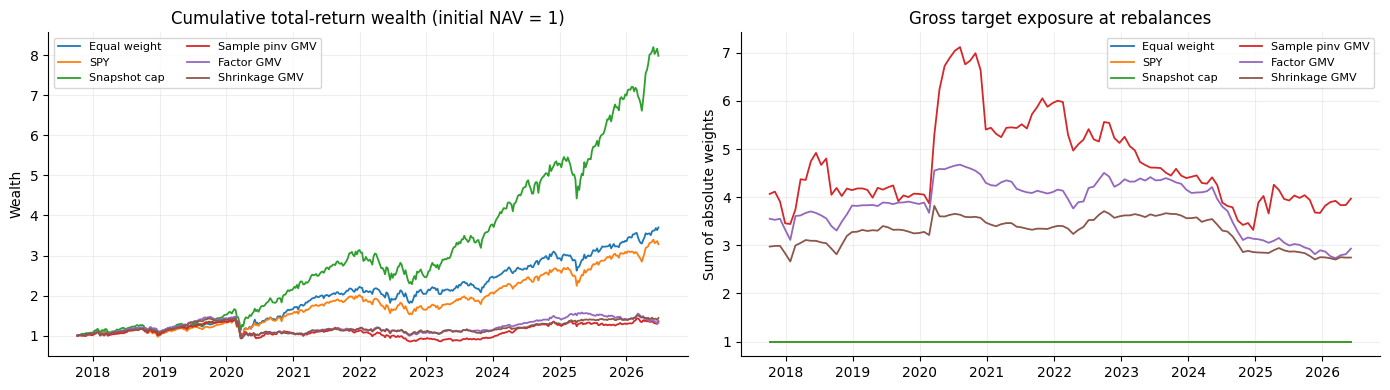

In [8]:
# Optimize the three unconstrained books under their own covariance at every signal date.
gmv_names = ['Sample pinv GMV', 'Factor GMV', 'Shrinkage GMV']
gmv_weights = {label: [] for label in gmv_names}
gmv_predictions = {label: [] for label in gmv_names}
for date in rebalance_dates:
    x, _ = window_at(date)
    sample = x.cov().to_numpy()
    model = weekly_models[date]
    factor = factor_covariance(model)
    shrunk = 0.5 * sample + 0.5 * np.diag(np.diag(sample))
    candidates = {
        'Sample pinv GMV': (sample_gmv_weights[date], sample),
        'Factor GMV': (normalize_gmv(factor_solve(model, ones)), factor),
        'Shrinkage GMV': (spd_gmv(shrunk), shrunk),
    }
    for label, (weights, cov) in candidates.items():
        gmv_weights[label].append(weights)
        gmv_predictions[label].append(np.sqrt(52 * weights @ cov @ weights))
for label in gmv_names:
    weights = pd.DataFrame(gmv_weights[label], index=rebalance_dates, columns=tickers)
    books[label] = make_book(weights, gmv_predictions[label])
gmv_metrics = report_books({label: books[label] for label in gmv_names})

# Total-return wealth and gross exposure reveal different aspects of implementation risk.
plot_names = ['Equal weight', 'SPY', 'Snapshot cap'] + gmv_names
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for label in plot_names:
    book = books[label]
    total = book['excess'] + rf.reindex(oos_dates)
    wealth = pd.concat([pd.Series([1.0], index=[rebalance_dates[0]]), (1 + total).cumprod()])
    axes[0].plot(wealth.index, wealth, label=label, linewidth=1.3)
    axes[1].plot(rebalance_dates, book['weights'].abs().sum(axis=1), label=label, linewidth=1.3)
axes[0].set(title='Cumulative total-return wealth (initial NAV = 1)', ylabel='Wealth')
axes[1].set(title='Gross target exposure at rebalances', ylabel='Sum of absolute weights')
axes[0].legend(fontsize=8, ncol=2)
axes[1].legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


## 3.3

Build the long-only GMV under your factor covariance with NNLS in the regression form. Report the same metrics.

#### NNLS Formulation

For the long-only tangency portfolio, NNLS of a constant on the return panel gives the weights, as in *MV Optimization via Regression*. For the GMV under any covariance $\Sigma = \boldsymbol{L}\boldsymbol{L}'$ (a Cholesky or eigenvalue factor), the variance is $\lVert \boldsymbol{L}'\boldsymbol{w} \rVert^2$. Stack the rows of $\boldsymbol{L}'$ with one additional row $\kappa\,\mathbf{1}'$ and a target vector of zeros with a final entry $\kappa$: the least-squares objective becomes $\boldsymbol{w}'\Sigma\boldsymbol{w} + \kappa^2(1 - \mathbf{1}'\boldsymbol{w})^2$. With $\kappa$ large relative to the return scale, NNLS on that system gives the long-only GMV up to a rescaling of the weights to sum to one.


Solve the stacked regression with $\kappa=100\max_i\sqrt{\Sigma_{F,ii}}$ and normalize the nonnegative solution to unit sum. Along any nonnegative unit-budget direction $u$, the optimal scale is $\kappa^2/(\kappa^2+u'\Sigma_Fu)$; the minimized penalty is increasing in $u'\Sigma_Fu$. Thus normalization preserves the long-only GMV direction in exact arithmetic, rather than merely hoping a finite penalty enforces the budget.

In [9]:
def long_only_gmv(cov):
    """Solve the nonnegative regression and normalize its optimal portfolio direction."""
    chol = np.linalg.cholesky(cov)
    kappa = 100 * np.sqrt(np.diag(cov).max())
    # Cholesky gives cov = L L'; use L' so the least-squares norm equals portfolio variance.
    design = np.vstack([chol.T, kappa * np.ones(len(cov))])
    target = np.append(np.zeros(len(cov)), kappa)
    weights, _ = nnls(design, target, maxiter=10 * len(cov))
    return normalize_gmv(weights)

long_weights, long_predictions = [], []
for date in rebalance_dates:
    # Reuse the same factor estimate as the unconstrained book; only the constraint changes.
    cov = factor_covariance(weekly_models[date])
    weights = long_only_gmv(cov)
    long_weights.append(weights)
    long_predictions.append(np.sqrt(52 * weights @ cov @ weights))
long_frame = pd.DataFrame(long_weights, index=rebalance_dates, columns=tickers)
books['Long-only factor GMV'] = make_book(long_frame, long_predictions)
long_metrics = report_books({'Long-only factor GMV': books['Long-only factor GMV']})
gmv_names = ['Sample pinv GMV', 'Factor GMV', 'Shrinkage GMV', 'Long-only factor GMV']
gmv_metrics = pd.concat([gmv_metrics.loc[gmv_names[:3]], long_metrics])


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Long-only factor GMV,4.52%,14.53%,0.31,-31.10%,8.52%,1.71


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Long-only factor GMV,1.00,1.00,36.2,2.06,12.73%,0.062


## 3.4

Compare the portfolios in 3.2 and 3.3.

- Which covariance produced the lowest realized volatility? How does realized volatility compare with predicted volatility?
- How did stabilization affect gross exposure, turnover, and concentration? In which years did it perform worst?
- What changed under the long-only constraint? Explain the result.


In [10]:
# Separate the worst return year from the year with the largest risk-underprediction ratio.
annual_records = []
for label in gmv_names:
    book = books[label]
    for year, r in book['excess'].groupby(book['excess'].index.year):
        predicted = book['predicted'][book['predicted'].index.year == year].mean()
        annual_records.append({'Book': label, 'Year': year, 'Weeks': len(r),
                               'Total return': (1 + r + rf.reindex(r.index)).prod() - 1,
                               'Realized vol': r.std(ddof=1)*np.sqrt(52),
                               'Realized/predicted': r.std(ddof=1)*np.sqrt(52)/predicted})
annual_gmv = pd.DataFrame(annual_records)
worst_years = pd.concat([
    annual_gmv.loc[annual_gmv.groupby('Book')['Total return'].idxmin()].assign(Criterion='Lowest return'),
    annual_gmv.loc[annual_gmv.groupby('Book')['Realized/predicted'].idxmax()].assign(Criterion='Largest risk miss')
]).set_index(['Book', 'Criterion'])
show_table(worst_years, {'Year': '{:.0f}', 'Weeks': '{:.0f}', 'Total return': '{:.2%}',
                         'Realized vol': '{:.2%}', 'Realized/predicted': '{:.2f}'},
           'Worst calendar-year observations; 2017 and 2026 are partial years')


,,Year,Weeks,Total return,Realized vol,Realized/predicted
Book,Criterion,,,,,
Factor GMV,Lowest return,2020,52,-26.15%,28.53%,6.12
Long-only factor GMV,Lowest return,2022,52,-5.21%,17.77%,1.81
Sample pinv GMV,Lowest return,2020,52,-20.94%,26.89%,2.54
Shrinkage GMV,Lowest return,2020,52,-24.76%,29.32%,4.62
Factor GMV,Largest risk miss,2020,52,-26.15%,28.53%,6.12
Long-only factor GMV,Largest risk miss,2018,52,-0.27%,14.57%,2.60
Sample pinv GMV,Largest risk miss,2020,52,-20.94%,26.89%,2.54
Shrinkage GMV,Largest risk miss,2020,52,-24.76%,29.32%,4.62


In [11]:
# Link the implementation trade-offs to the measured changes, not just the Sharpe ranking.
lowest = gmv_metrics['Realized vol'].idxmin()
sample_row, shrink_row = gmv_metrics.loc['Sample pinv GMV'], gmv_metrics.loc['Shrinkage GMV']
factor_row, long_row = gmv_metrics.loc['Factor GMV'], gmv_metrics.loc['Long-only factor GMV']
display(Markdown('### What stabilization and constraints changed\n\n'
    f'- **Lowest realized GMV volatility:** {lowest}, {gmv_metrics.loc[lowest, "Realized vol"]:.2%}. '
    'The realized/predicted column, not the ranking alone, measures delivery of the risk promise.\n'
    f'- **Shrinkage versus sample pinv:** gross {sample_row["Gross"]:.2f} to {shrink_row["Gross"]:.2f}; '
    f'annual one-way turnover {sample_row["Annual one-way turnover"]:.2f} to {shrink_row["Annual one-way turnover"]:.2f}; '
    f'average largest absolute weight {sample_row["Average max |w|"]:.2%} to {shrink_row["Average max |w|"]:.2%}. '
    'Stabilization reduces gross exposure and turnover here, but does not reduce the largest weight or absolute-weight HHI. '
    'The worst-year table distinguishes losing money from underestimating risk.\n'
    f'- **Long-only versus unconstrained factor:** gross {factor_row["Gross"]:.2f} to {long_row["Gross"]:.2f}; '
    f'positions {factor_row["Positions"]:.1f} to {long_row["Positions"]:.1f}; '
    f'predicted vol {factor_row["Predicted vol"]:.2%} to {long_row["Predicted vol"]:.2%}; '
    f'realized vol {factor_row["Realized vol"]:.2%} to {long_row["Realized vol"]:.2%}. '
    'Removing negative hedges restricts the feasible set, so estimated minimum risk cannot fall. '
    'It can nevertheless improve out-of-sample calibration by preventing unstable offsetting positions. '
    'NNLS often concentrates capital in a smaller defensive active set: long-only is not the same as diversified.\n\n'
    '**Carry-forward choice remains the diagonal-residual factor covariance**, with the long-only constraint '
    'preferred for the implementable risk-control exercise. No covariance is accepted merely because its realized Sharpe is high.'))


### What stabilization and constraints changed

- **Lowest realized GMV volatility:** Shrinkage GMV, 14.05%. The realized/predicted column, not the ranking alone, measures delivery of the risk promise.
- **Shrinkage versus sample pinv:** gross 4.68 to 3.27; annual one-way turnover 12.23 to 5.04; average largest absolute weight 4.41% to 5.36%. Stabilization reduces gross exposure and turnover here, but does not reduce the largest weight or absolute-weight HHI. The worst-year table distinguishes losing money from underestimating risk.
- **Long-only versus unconstrained factor:** gross 3.84 to 1.00; positions 457.0 to 36.2; predicted vol 3.96% to 8.52%; realized vol 14.46% to 14.53%. Removing negative hedges restricts the feasible set, so estimated minimum risk cannot fall. It can nevertheless improve out-of-sample calibration by preventing unstable offsetting positions. NNLS often concentrates capital in a smaller defensive active set: long-only is not the same as diversified.

**Carry-forward choice remains the diagonal-residual factor covariance**, with the long-only constraint preferred for the implementable risk-control exercise. No covariance is accepted merely because its realized Sharpe is high.

# 4. The Mean Input


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Isolate expected-return estimation while fixing the factor covariance, 104-week windows, and rebalance dates.
2. **Methods:** Use sample means, 50% shrinkage toward their cross-sectional grand mean, and SPY-beta-implied CAPM means. Scale every tangency direction to 10% predicted volatility rather than a unit budget.
3. **Outputs/meaning:** Realized volatility is 42.0%, 42.8%, and 12.0%, respectively. Mean uncertainty is comparable to cross-sectional mean dispersion; half shrinkage leaves most relative bets intact. Woodbury separates stock signals from factor hedges, while the single-factor derivation shows why CAPM favors beta relative to residual variance.

**Subquestion guide:** **4.1** asks for three books' complete metrics and an algebraic description of full shrinkage, without backtesting it. **4.2** quantifies mean-estimation noise, explains each anchor through the inverse-covariance decomposition, and derives the single-factor CAPM allocation.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 固定因子协方差、104 周窗口和再平衡日期，只改变预期收益估计。
2. **方法：** 使用样本均值、向横截面总均值收缩 50%，以及 SPY 贝塔乘市场溢价的 CAPM 均值。切点方向统一缩放到预测年化波动 10%，而不是令权重之和等于 1。
3. **输出与含义：** 三种组合实际波动分别为 42.0%、42.8%、12.0%。均值估计噪声与横截面差异量级接近；收缩一半仍保留多数相对押注。Woodbury 分解解释选股与因子对冲，单因子推导则说明 CAPM 如何按贝塔相对于残差方差分配权重。

**小题导读：** **4.1** 报告三种组合的完整指标，并只用代数说明完全收缩组合，不额外回测。**4.2** 量化均值噪声，用逆协方差分解解释不同锚的影响，并推导单因子 CAPM 配置。

## 4.1

Build the tangency portfolio under your factor covariance with three return inputs: the sample means of the window; the sample means shrunk halfway toward the grand mean, $a = 0.5$; and the CAPM-implied means, $\beta_i$ times the window's mean market excess return, with $\beta_i$ estimated on SPY over the window. Scale each to 10% ex-ante volatility.

* Report the book metrics, including predicted and realized volatility.
* State what the $a = 1$ book is without running it.

#### Mean Shrinkage

Shrinkage toward the grand mean across names with weight $a$: $\tilde{\mu}_i^{(a)} = (1-a)\,\hat{\tilde\mu}_i + a\,\bar{\hat{\tilde\mu}}$.


In [12]:
# Hold covariance and estimation dates fixed so only the mean input differs between books.
tangency_names = ['Tangency sample mean', 'Tangency half shrink', 'Tangency CAPM']
tangency_weights = {label: [] for label in tangency_names}
tangency_predictions = {label: [] for label in tangency_names}
mean_uncertainty_rows = []
for date in rebalance_dates:
    x, _ = window_at(date)
    model = weekly_models[date]
    mu = x.mean().to_numpy()
    market = spyx.reindex(x.index).to_numpy()
    mc = market - market.mean()
    # Estimate SPY betas on this window only; the full-sample betas in Section 6 are not used.
    beta_market = mc @ (x.to_numpy() - mu) / (mc @ mc)
    inputs = [mu, 0.5*mu + 0.5*mu.mean(), beta_market*market.mean()]
    for label, mean in zip(tangency_names, inputs):
        direction = factor_solve(model, mean)
        variance = factor_variance(model, direction[:, None])[0]
        if variance <= 0:
            raise ValueError(f'Cannot volatility-scale a zero tangency direction on {date}.')
        # Scale volatility, not the budget: net exposure may differ across mean specifications.
        weights = direction * 0.10 / np.sqrt(52 * variance)
        tangency_weights[label].append(weights)
        tangency_predictions[label].append(np.sqrt(52*factor_variance(model, weights[:, None])[0]))
    # Record Section 4.2's uncertainty inputs while this historical window is already in memory.
    typical_vol = x.std(ddof=1).median()*np.sqrt(52)
    se_annual_mean = typical_vol*np.sqrt(52/len(x))
    cross_mean_sd = (x.mean()*52).std(ddof=1)
    mean_uncertainty_rows.append((date, typical_vol, se_annual_mean, cross_mean_sd, se_annual_mean/cross_mean_sd))
for label in tangency_names:
    w = pd.DataFrame(tangency_weights[label], index=rebalance_dates, columns=tickers)
    books[label] = make_book(w, tangency_predictions[label])
tangency_metrics = report_books({label: books[label] for label in tangency_names})


,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Tangency sample mean,14.36%,42.03%,0.34,-76.72%,10.00%,4.20
Tangency half shrink,12.93%,42.77%,0.30,-80.67%,10.00%,4.28
Tangency CAPM,3.62%,11.97%,0.30,-32.71%,10.00%,1.20


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Tangency sample mean,10.00,0.50,457.0,22.53,13.15%,0.004
Tangency half shrink,9.98,1.11,457.0,22.27,13.46%,0.004
Tangency CAPM,1.87,0.56,457.0,3.97,2.62%,0.004


**Without running $a=1$.** The input is $\bar\mu\mathbf1$, so the direction is $\bar\mu\Sigma_F^{-1}\mathbf1$. For positive $\bar\mu$, this is the GMV direction scaled to 10% volatility, **not** necessarily to net exposure one. A negative grand mean reverses its sign; a zero grand mean has no nonzero tangency direction and cannot be scaled to positive volatility.

## 4.2

Compute the standard error of a 104-week annualized mean for a name of typical volatility and compare it with the cross-sectional standard deviation of the window's annualized means. Use the two components of $\Sigma^{-1}\tilde\mu$ under each anchor to explain how the books in 4.1 change with $a$. Derive the tangency weights when the return input is the CAPM-implied mean and the covariance is a single-factor model with diagonal residuals, and say which kinds of names such a book favors.


In [13]:
# Compare estimation noise with the cross-sectional differences the optimizer is asked to exploit.
uncertainty = pd.DataFrame(mean_uncertainty_rows, columns=['Date', 'Typical annual vol', 'SE annual mean',
                                                         'Cross-sectional mean SD', 'SE / cross-sectional SD']).set_index('Date')
focus_typical = X0.std(ddof=1).median()*np.sqrt(52)
focus_se = focus_typical*np.sqrt(52/WINDOW)
focus_cross_sd = (X0.mean()*52).std(ddof=1)
uncertainty_summary = pd.DataFrame([
    [focus_typical, focus_se, focus_cross_sd, focus_se/focus_cross_sd],
    uncertainty.median().to_list(),
], index=['Window ending 2025-12-26', 'Median across rolling windows'], columns=uncertainty.columns)
show_table(uncertainty_summary, {c: ('{:.2f}' if c.startswith('SE /') else '{:.2%}') for c in uncertainty.columns})


,Typical annual vol,SE annual mean,Cross-sectional mean SD,SE / cross-sectional SD
Window ending 2025-12-26,26.05%,18.42%,20.95%,0.88
Median across rolling windows,27.98%,19.79%,17.67%,1.12


### Mean uncertainty and the two components

Under an IID approximation, $\operatorname{SE}(52\hat\mu)=52s_{\rm weekly}/\sqrt{104}=\sigma_{\rm annual}\sqrt{52/104}$. The table takes median individual volatility as typical. In the diagnostic window, the annual-mean standard error is **18.4 percentage points**, versus **21.0 points** of cross-sectional mean dispersion; across rolling windows the median noise-to-dispersion ratio is **1.12**. Thus sampling uncertainty is of the same order as the differences being optimized. Cross-sectional dispersion mixes genuine variation and estimation error; correlation between names means this comparison does not identify the fraction of true alpha.

The half-shrunk book retains almost the same gross exposure as the sample-mean book (about 10), and realized risk rises slightly rather than falling. Its direction is still dominated by estimated relative means and the factor covariance's cheap hedges. CAPM reduces gross exposure to about 1.86, annual turnover to 3.97, and realized volatility to 11.97%; this is a substantial stabilization, not evidence that all CAPM assumptions hold. The grand mean changes net exposure more than it removes these relative bets.

For $\Sigma=D+B'\Sigma_fB$, Woodbury gives two economically different terms:
$$
q(m)=\Sigma^{-1}m
=\underbrace{D^{-1}m}_{\text{residual-precision stock signal}}
-\underbrace{D^{-1}B'(\Sigma_f^{-1}+BD^{-1}B')^{-1}BD^{-1}m}_{\text{common-factor hedge}}.
$$
Both terms are linear in the mean input. With **grand-mean anchoring**, $q_a=(1-a)q(\hat\mu)+a\bar\mu q(\mathbf1)$: the residual signal increasingly ranks low residual variances, while the hedge adjusts their common exposures. With a **CAPM anchor**, $m_C=\hat\beta\hat\mu_M$, a hypothetical interpolation is $q_a=(1-a)q(\hat\mu)+a\hat\mu_Mq(\hat\beta)$; the 4.1 CAPM book is its endpoint. These are different restrictions, not interchangeable ways to damp every weight. Subsequent volatility normalization is nonlinear, so the final 50%-shrunk weights are not the arithmetic average of two fully scaled portfolios.

For a **single market factor** with diagonal residuals,
$$\Sigma=\sigma_M^2\beta\beta'+D,\qquad
\Sigma^{-1}(\beta\mu_M)=\frac{\mu_M}{1+\sigma_M^2\beta'D^{-1}\beta}D^{-1}\beta.$$
At target volatility $v$, the weights therefore satisfy
$$w^*=\operatorname{sign}(\mu_M)\frac{v}{\sqrt{52\,q'\Sigma q}}q,\qquad q=D^{-1}\beta,$$
provided $\mu_M\ne0$. It favors large positive beta **per unit residual variance**, not high sample mean per se; negative-beta names are short when the premium is positive. Very low residual variance can still generate concentration. The ten-sector covariance in 4.1 is not this single-factor special case, so its CAPM-input weights need not follow this simple ranking exactly. CAPM shrinkage eliminates individual estimated alphas, not all estimation or model risk.

# 5. The Book's Own Risk

Switch to daily data. Weights in force on a trading day are those of the most recent weekly rebalance. Map tickers between the two panels; drop `ECHO`, `FLEX`, `MRVL` and `FISV`, leaving 453 names, and rescale the remaining weights to the sum they had before the drop. The daily panel holds total returns and no daily bill series ships, so each book's daily return is its total return, and every VaR forecast and hit test is on that total return.


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Project the long-only factor GMV and equal-weight control onto 453 daily names, mapping ticker punctuation, removing the four specified stocks, and restoring original net exposure. Use total returns because no daily bill series ships.
2. **Methods:** At each close, revalue 252 past trading days with current weights and forecast next-day historical, factor-normal, and 0.94-EWMA VaR. Holiday signal labels map to the preceding trading close; realized returns are strictly later.
3. **Outputs/meaning:** The chosen book's historical/factor-normal breach rates are 7.14%/7.46%, versus 5.31%/5.54% for equal weight. Both chosen-book rates exceed 31% in the 51-day COVID window. Tail-loss comparisons expose severity errors that an average breach rate can hide.

**Subquestion guide:** **5.1** constructs three forecasts for two explicitly named books. **5.2** reports days, breaches, and realized versus implied CVaR by regime. **5.3** diagnoses quantile, variance, and tail-shape errors, overlapping estimation/selection data, and the limitations of short windows.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 将只做多因子 GMV 和等权组合映射到 453 只日频股票，统一代码分隔符、剔除指定四只股票并恢复原净敞口。没有日频国库券数据，因此使用总收益。
2. **方法：** 每个收盘时点用当前权重重算过去 252 个交易日收益，预测次日历史法、因子正态法和 0.94-EWMA VaR。节假日信号标签映射到前一交易日收盘，实际收益严格在预测之后。
3. **输出与含义：** 所选组合历史法／因子正态法超限率为 7.14%／7.46%，等权为 5.31%／5.54%；在 51 天疫情窗口中，所选组合两种方法都超过 31%。尾部损失比较揭示平均超限率可能掩盖的严重度误差。

**小题导读：** **5.1** 为两个明确命名的组合构造三种预测。**5.2** 分时期报告天数、超限及实际与隐含 CVaR。**5.3** 从分位数、方差、尾部分布、样本重叠和短窗口限制解释误差。

## 5.1

Carry forward one book from Section 3 or 4 and name it; keep equal weight as the control. For each trading day from the first rebalance date, forecast the next day's 5% VaR of each book from the trailing 252 trading days, three ways:

* the historical quantile of the book's return with current weights
* normal VaR with your factor covariance fit on the daily sector returns from the `total returns` sheet
* EWMA with $\lambda = 0.94$ on the book's daily return with current weights


### One-day 5% VaR on total returns

**Carried book: Long-only factor GMV.** Both tested books have unit net exposure, avoiding an unidentified daily cash-return assumption. Remove ECHO, FLEX, MRVL, and FISV from the weekly weights and multiply survivors by original net exposure divided by surviving net exposure; equal weight becomes $1/453$. This is a prescribed, slightly different book, not the unchanged 457-name return series.

**Timing:** A forecast formed at trading close $t$ uses the 252 observations ending at $t$ and is matched only to the return at $t+1$. Weekly signal dates are closing labels; a holiday Friday maps to the preceding available trading close. New weights first earn the following trading day's return. Historical observations are reweighted with the **current** weights, not concatenated from historical strategy returns. The same convention is used for every model.

**Definitions:** $q_{.05}$ is a return quantile, so positive-loss VaR is $-q_{.05}$ and a breach is $r_{t+1}<q_{.05}$. Historical VaR uses linear empirical quantiles, with implied CVaR equal to minus the mean of observations at or below that quantile. Factor-normal VaR uses the ten-sector diagonal-residual covariance fit to daily **total** returns, with $q=\bar r+z_{.05}\sigma$ and $\mathrm{CVaR}=-\bar r+\sigma\phi(z_{.05})/.05$. EWMA uses the same trailing mean and normalized weights proportional to $0.94^{\rm age}$ on squared demeaned returns across the 252-day window. This is a finite-window EWMA, not a second factor fit. No daily bill proxy or the sector workbook's misleading excess-return sheet is used.

In [14]:
# Harmonize ticker conventions and apply exactly the exclusions required by the brief.
DROP_DAILY = ['ECHO', 'FLEX', 'MRVL', 'FISV']
daily_tickers = tickers[~tickers.isin(DROP_DAILY)]
daily_all = pd.read_parquet(DAILY).sort_index()
daily_returns = daily_all.loc[:, [ticker.replace('/', '-') for ticker in daily_tickers]].copy()
daily_returns.columns = daily_tickers
# Daily stocks and factors must both be total returns; no daily bill proxy is introduced.
daily_factors = pd.read_excel(SECTOR_DAILY, sheet_name='total returns', index_col='date')
daily_factors = daily_factors.reindex(daily_returns.index)[factor_names]
ALPHA, DAILY_WINDOW, EWMA_LAMBDA = 0.05, 252, 0.94
z_alpha = norm.ppf(ALPHA)
ewma_weights = EWMA_LAMBDA ** np.arange(DAILY_WINDOW - 1, -1, -1)
ewma_weights /= ewma_weights.sum()

def daily_weight_schedule(weekly_weights):
    kept = weekly_weights.loc[:, daily_tickers].copy()
    original_net, remaining_net = weekly_weights.sum(axis=1), kept.sum(axis=1)
    if remaining_net.abs().lt(1e-12).any():
        raise ValueError('Cannot restore the original net exposure after daily-universe exclusions.')
    # Restore the original book's net investment after dropping unavailable names.
    kept = kept.mul(original_net / remaining_net, axis=0)
    # A holiday Friday labels information already known at the preceding trading close.
    locations = daily_returns.index.searchsorted(kept.index, side='right') - 1
    if (locations < 0).any():
        raise ValueError('A weekly signal precedes the daily history.')
    kept.index = daily_returns.index[locations]
    return kept.reindex(daily_returns.index).ffill()

def forecast_daily(collection):
    """Batch books so each day's sector factor model is estimated only once."""
    labels = list(collection)
    schedules = {label: daily_weight_schedule(book['weights']) for label, book in collection.items()}
    assets = daily_returns.to_numpy()
    factors = daily_factors.to_numpy()
    first = daily_returns.index.searchsorted(rebalance_dates[0])
    rows = []
    for i in range(max(first, DAILY_WINDOW-1), len(daily_returns)-1):
        x = assets[i-DAILY_WINDOW+1:i+1]
        f = factors[i-DAILY_WINDOW+1:i+1]
        if not np.isfinite(x).all() or not np.isfinite(f).all():
            raise ValueError(f'Missing daily estimation observations at {daily_returns.index[i]}.')
        w = np.column_stack([schedules[label].iloc[i].to_numpy() for label in labels])
        if not np.isfinite(w).all():
            raise ValueError('Daily weight schedule has not started for every book.')
        # Revalue the entire trailing history with today's targets, not yesterday's strategy weights.
        past = x @ w
        mean = past.mean(axis=0)
        realized = assets[i+1] @ w  # Match only the next trading day's return to this forecast.
        factor_model, _ = fit_factor(x, f)
        factor_sigma = np.sqrt(factor_variance(factor_model, w))
        ewma_sigma = np.sqrt(ewma_weights @ ((past - mean)**2))
        # Historical quantiles are empirical; the other two methods impose normal tails.
        hist_q = np.quantile(past, ALPHA, axis=0, method='linear')
        for j, label in enumerate(labels):
            # CVaR is reported as a positive loss; EWMA CVaR is not required in the brief.
            hist_es = -past[past[:, j] <= hist_q[j], j].mean()
            forecasts = [
                ('Historical', hist_q[j], hist_es, past[:, j].std(ddof=1)),
                ('Factor normal', mean[j] + z_alpha*factor_sigma[j],
                 -mean[j] + factor_sigma[j]*norm.pdf(z_alpha)/ALPHA, factor_sigma[j]),
                ('EWMA', mean[j] + z_alpha*ewma_sigma[j], np.nan, ewma_sigma[j]),
            ]
            for method, quantile, expected_shortfall, sigma in forecasts:
                rows.append((daily_returns.index[i], daily_returns.index[i+1], label, method,
                             realized[j], quantile, expected_shortfall, sigma, realized[j] < quantile))
    return pd.DataFrame(rows, columns=['Origin', 'Date', 'Book', 'Method', 'Return', 'Quantile',
                                       'Forecast CVaR', 'Sigma', 'Hit'])

daily_risk = forecast_daily({label: books[label] for label in ['Long-only factor GMV', 'Equal weight']})
display(Markdown(f'**Daily coverage:** {len(daily_tickers)} names; '
                 f'{daily_risk.Date.nunique()} realized trading days, '
                 f'{daily_risk.Date.min().date()} to {daily_risk.Date.max().date()}. '
                 'The daily panel ends earlier than the final weekly observation.'))


**Daily coverage:** 453 names; 2186 realized trading days, 2017-10-09 to 2026-06-22. The daily panel ends earlier than the final weekly observation.

## 5.2

Run the hit test for each book and forecast over the full period and within these windows: 2020-02-19 to 2020-04-30; calendar 2022; calendar 2023. Report

* the breach rate in each cell and the number of days in each window
* for the historical and factor-normal forecasts, the realized conditional VaR on the breach days against the CVaR the forecast implies


### Breach frequency and conditional tail loss

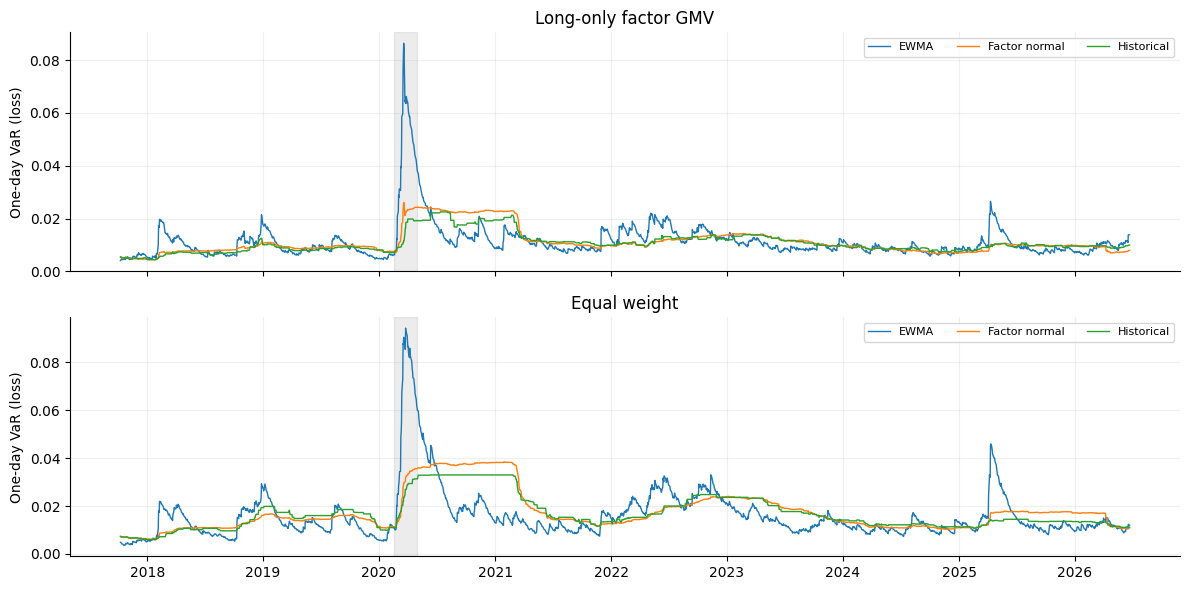

In [15]:
# Regime membership refers to the realized loss date, not the preceding forecast origin.
regimes = {'Full period': (None, None), 'COVID shock': ('2020-02-19', '2020-04-30'),
           '2022': ('2022-01-01', '2022-12-31'), '2023': ('2023-01-01', '2023-12-31')}

def summarize_hits(risk):
    records = []
    for regime, (start, end) in regimes.items():
        subset = risk if start is None else risk[risk.Date.between(start, end)]
        for (book, method), group in subset.groupby(['Book', 'Method']):
            # Every method selects its own breach days; compare severity on that same subset.
            hits = group[group.Hit]
            n, count = len(group), len(hits)
            rate = count/n
            # Wilson intervals are descriptive IID references, not dependence-robust tests.
            z = norm.ppf(0.975)
            center = (rate + z*z/(2*n)) / (1 + z*z/n)
            half = z*np.sqrt(rate*(1-rate)/n + z*z/(4*n*n)) / (1 + z*z/n)
            records.append({'Regime': regime, 'Book': book, 'Method': method, 'Days': n, 'Hits': count,
                            'Breach rate': rate, 'IID interval low': center-half, 'IID interval high': center+half,
                            'Average VaR': -group.Quantile.mean(),
                            'Realized CVaR': -hits.Return.mean(),
                            'Forecast CVaR (hit days)': hits['Forecast CVaR'].mean(),
                            'Forecast CVaR (all days)': group['Forecast CVaR'].mean()})
    return pd.DataFrame(records)

hit_summary = summarize_hits(daily_risk)
hit_display = hit_summary.set_index(['Regime', 'Book', 'Method'])
display(Markdown('### Breach frequency and conditional tail loss'))
show_table(hit_display[['Days', 'Hits', 'Breach rate', 'IID interval low', 'IID interval high']],
           {'Days': '{:.0f}', 'Hits': '{:.0f}', 'Breach rate': '{:.2%}',
            'IID interval low': '{:.2%}', 'IID interval high': '{:.2%}'},
           'Target = 5%; regime membership is based on the realized return date')
tail_display = hit_summary[hit_summary.Method.isin(['Historical', 'Factor normal'])].set_index(['Regime', 'Book', 'Method'])
show_table(tail_display[['Average VaR', 'Realized CVaR', 'Forecast CVaR (hit days)', 'Forecast CVaR (all days)']],
           '{:.2%}', 'Daily positive-loss units; -- means no breach days, not zero tail risk')

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
for ax, label in zip(axes, ['Long-only factor GMV', 'Equal weight']):
    for method, subset in daily_risk[daily_risk.Book == label].groupby('Method'):
        ax.plot(subset.Date, -subset.Quantile, label=method, linewidth=1)
    ax.set(title=label, ylabel='One-day VaR (loss)')
    ax.axvspan(pd.Timestamp('2020-02-19'), pd.Timestamp('2020-04-30'), color='grey', alpha=0.15)
    ax.legend(ncol=3, fontsize=8)
fig.tight_layout()
plt.show()


## 5.3

Which forecasts miss their target breach rate, for which portfolio, and through which estimated risk quantity? What does sharing one window between the choice of weights and the estimate of their risk do to the historical quantile? What can the number of days in each regime window establish, and what can it not?


In [16]:
# Report both the frequency miss and the volatility scale behind each estimated cutoff.
risk_diagnosis = []
for _, row in hit_summary[hit_summary.Regime == 'Full period'].iterrows():
    risk_diagnosis.append(f'- **{row["Book"]} / {row["Method"]}:** {row["Breach rate"]:.2%} breaches '
                          f'({row["Hits"]}/{row["Days"]}), {row["Breach rate"]-ALPHA:+.2%} relative to the target.')
display(Markdown('### What the misses diagnose\n\n' + '\n'.join(risk_diagnosis)))
daily_scale_rows = []
for (label, method), group in daily_risk.groupby(['Book', 'Method']):
    daily_scale_rows.append({'Book': label, 'Method': method,
                             'Realized annual vol': group.Return.std(ddof=1)*np.sqrt(252),
                             'Mean forecast annual vol': group.Sigma.mean()*np.sqrt(252)})
daily_scales = pd.DataFrame(daily_scale_rows).set_index(['Book', 'Method'])
daily_scales['Realized / mean forecast'] = daily_scales['Realized annual vol'] / daily_scales['Mean forecast annual vol']
show_table(daily_scales, {'Realized annual vol': '{:.2%}', 'Mean forecast annual vol': '{:.2%}',
                         'Realized / mean forecast': '{:.2f}'},
           'Scale diagnostic: historical sigma is the current-weight sample standard deviation, not its VaR model')


### What the misses diagnose

- **Equal weight / EWMA:** 6.54% breaches (143/2186), +1.54% relative to the target.
- **Equal weight / Factor normal:** 5.54% breaches (121/2186), +0.54% relative to the target.
- **Equal weight / Historical:** 5.31% breaches (116/2186), +0.31% relative to the target.
- **Long-only factor GMV / EWMA:** 6.95% breaches (152/2186), +1.95% relative to the target.
- **Long-only factor GMV / Factor normal:** 7.46% breaches (163/2186), +2.46% relative to the target.
- **Long-only factor GMV / Historical:** 7.14% breaches (156/2186), +2.14% relative to the target.

**Observed misses.** Full-period historical and factor-normal forecasts are approximately calibrated for equal weight (5.31% and 5.54%), but understate the chosen book's lower-tail frequency (7.14% and 7.46%). EWMA exceeds target for both books (6.54% and 6.95%). COVID breaches jump to roughly 29–31% for the slow historical/factor models, versus 16–20% for EWMA. In 2022 all three methods exceed 5% for both books; in 2023 historical/factor forecasts become conservative (1.2% for equal weight and 2.8% for the chosen book), whereas EWMA still exceeds 5%. A full-sample average conceals this regime reversal.

**Which estimated quantity?** Historical VaR estimates a **quantile** from about 13 lower-tail observations per window: low fitted current-weight variance and stale tail observations can both compress it. Factor-normal VaR imposes a **covariance** and Gaussian **tail shape**. The chosen book realizes 14.68% annualized daily volatility against an average factor forecast of 11.25% (ratio 1.30); equal weight is 19.35% versus 17.46% (1.11). Thus scale underprediction is materially larger for the optimized book. Its full-period breach loss is 1.70% per day versus matched normal CVaR of 1.22%; equal weight is 2.50% versus 1.84%. Historical CVaR gaps are smaller (1.75% versus 1.50% for the chosen book; 2.55% versus 2.29% for equal weight), so frequency calibration alone misses severity error. These diagnostics do not uniquely identify time variation versus tail-shape error. EWMA changes the **conditional variance's adaptation speed**, not Gaussian tail shape: it reacts faster after a shock without necessarily anticipating its first days.

Choosing weights and estimating their historical risk on the same observations rewards directions with unusually small in-sample losses. Revaluing that optimized book on the same history is not an independent risk validation. Here the 104-week weekly choice window and the 252-day daily risk window are not identical, but overlap substantially; changing sampling frequency does not remove the selection channel. The equal-weight control helps separate that channel from shared market/regime misspecification.

Realized CVaR is the average loss **on each model's own breach dates**. The matching forecast-CVaR column averages predictions on those dates; the all-days column shows the unconditional forecast average. These are descriptive comparisons of severity, not formal expected-shortfall calibration tests; different models select different breach sets.

The COVID window contains only a few expected 5% breaches. Its hit rate can reveal a large failure during this episode, but cannot establish a stable tail probability or reliably rank small differences between estimators. Annual windows are larger yet still have relatively few tail events. Reported Wilson intervals assume independent Bernoulli hits; volatility clustering, overlapping estimation windows, and portfolio selection weaken that assumption. Neither a full-sample average near 5% nor inclusion of 5% in such an interval establishes conditional calibration.

# 6. Pricing the Names


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task/data:** Use all 573 weekly observations for 457 stock betas and means, and the 559-week common sample for the ten sector ETFs' joint-alpha test.
2. **Methods:** Regress annualized mean excess returns on SPY betas; compute the DFA chi-square statistic and a separately labeled finite-sample GRS reference. Compare the pricing pattern with the verified instructor's 49-industry page, not with HW4's different 25-portfolio cross section.
3. **Outputs/meaning:** Our slope is 14.02%, versus a 12.34% market premium, with a 0.33% intercept; sector alphas are not jointly rejected (p = 0.159). The instructor's industry chart instead has a shallow slope and substantial positive intercept. Different eras, aggregation, and survivor selection can explain the contrast; neither result proves exact pricing.

**Subquestion guide:** **6.1** reports the two CAPM tests with their correct samples, units, statistics, and degrees of freedom. **6.2** reconciles the tests, compares the industry case, and evaluates the assumptions behind Section 4's CAPM mean anchor.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求与数据：** 用全部 573 周估计 457 只股票的贝塔和均值，并用 559 周共同样本检验 10 个行业 ETF 的联合 alpha。
2. **方法：** 将年化平均超额收益对 SPY 贝塔回归，计算 DFA 卡方统计量，并单独标注有限样本 GRS 参照。比较对象为已核实的教师 49 行业网页，而不是 HW4 的另一组 25 个投资组合。
3. **输出与含义：** 本项目斜率 14.02%，市场溢价 12.34%，截距 0.33%，行业 alpha 不被联合拒绝（p = 0.159）。教师行业图则斜率较平、正截距较大。样本年代、组合聚合和幸存者选择可能解释差异；这些结果都不证明精确定价成立。

**小题导读：** **6.1** 按正确样本与单位报告两项检验及统计量、自由度。**6.2** 综合解释两项检验、比较行业案例，并评估第 4 题 CAPM 均值锚所依赖的假设。

## 6.1

Over the full weekly sample, estimate each of the 457 names' beta on SPY and run these two tests of the CAPM:

* Regress the names' mean excess returns on their betas. Report the slope and intercept beside the sample market premium.
* Run the joint test of zero alphas from the DFA case on the ten sector ETFs against SPY. Report the statistic, $p$-value, $T$, $N$ and degrees of freedom.


,Estimate
Cross-sectional intercept (annual),0.33%
Cross-sectional slope (annual),14.02%
SPY premium (annual),12.34%
R-squared,25.18%


,Statistic,p-value,T,N,Degrees of freedom
DFA H: asymptotic chi-square,14.3227,0.1588,559,10,10
GRS: finite-sample F reference,1.4066,0.1735,559,10,"(10, 548)"


,Annual alpha,Market beta
XLK,6.36%,1.179
XLI,-0.54%,1.048
XLF,-2.11%,1.080
XLRE,-4.26%,0.894
XLE,-1.69%,0.927
XLY,-3.52%,1.145
XLB,-2.89%,0.987
XLV,-0.69%,0.737
XLU,1.56%,0.635
XLP,-0.86%,0.569


Stock cross section: **T=573, N=457**, 2015-07-10 to 2026-06-26. Sector joint test: **T=559, N=10**, 2015-10-16 to 2026-06-26; XLRE availability determines the common start. No ETF returns are backfilled.

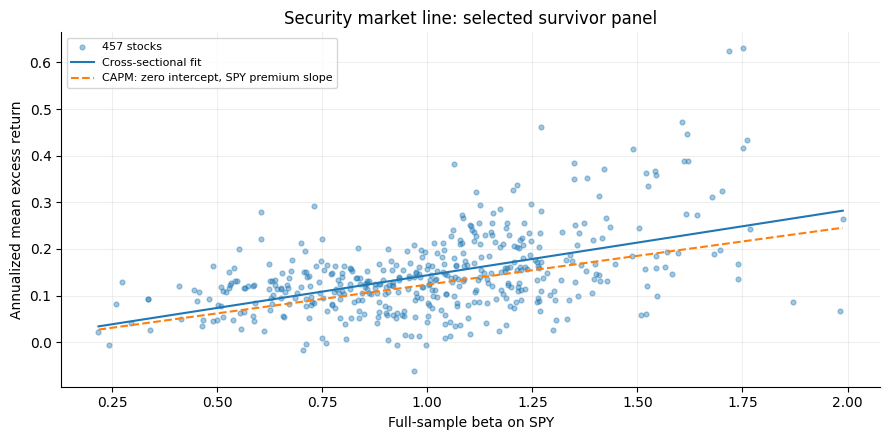

In [17]:
# Test 1: estimate every stock's beta on the same full weekly sample, then price the cross section.
market = spyx.to_numpy()
mc = market - market.mean()
betas_full = mc @ (rx.to_numpy() - rx.mean().to_numpy()) / (mc @ mc)
annual_means = rx.mean().to_numpy() * 52
cs_design = np.column_stack([np.ones(N), betas_full])
cs_intercept, cs_slope = np.linalg.lstsq(cs_design, annual_means, rcond=None)[0]
cs_fitted = cs_design @ np.array([cs_intercept, cs_slope])
cs_r2 = 1 - np.sum((annual_means-cs_fitted)**2)/np.sum((annual_means-annual_means.mean())**2)
market_premium = spyx.mean()*52
capm_cross_section = pd.Series({'Cross-sectional intercept (annual)': cs_intercept,
                               'Cross-sectional slope (annual)': cs_slope,
                               'SPY premium (annual)': market_premium,
                               'R-squared': cs_r2}, name='Estimate')
show_table(capm_cross_section.to_frame(), '{:.2%}')

# Test 2: use the ten ETFs' common available dates; do not backfill XLRE's missing early history.
joint_data = fx.join(spyx.rename('SPY')).dropna()
m = joint_data['SPY'].to_numpy()
y = joint_data[factor_names].to_numpy()
T_joint, N_joint, K_joint = len(y), y.shape[1], 1
design = np.column_stack([np.ones(T_joint), m])
coefficients = np.linalg.lstsq(design, y, rcond=None)[0]
alphas = coefficients[0]
residuals = y - design @ coefficients
residual_cov = residuals.T @ residuals / (T_joint - 1)
market_var = m.var(ddof=1)
# Follow the local DFA case's T-1 covariance convention and unannualized market Sharpe ratio.
H_dfa = T_joint / (1 + m.mean()**2/market_var) * alphas @ np.linalg.solve(residual_cov, alphas)
p_dfa = chi2.sf(H_dfa, N_joint)
# The exact GRS F reference uses T-denominator residual and factor moments.
residual_cov_ml = residuals.T @ residuals / T_joint
market_var_ml = np.var(m, ddof=0)
grs = (T_joint-N_joint-K_joint)/N_joint * (alphas @ np.linalg.solve(residual_cov_ml, alphas)) / (1+m.mean()**2/market_var_ml)
p_grs = f_dist.sf(grs, N_joint, T_joint-N_joint-K_joint)
joint_results = pd.DataFrame({
    'Statistic': [H_dfa, grs], 'p-value': [p_dfa, p_grs], 'T': [T_joint]*2, 'N': [N_joint]*2,
    'Degrees of freedom': [str(N_joint), f'({N_joint}, {T_joint-N_joint-K_joint})'],
}, index=['DFA H: asymptotic chi-square', 'GRS: finite-sample F reference'])
show_table(joint_results, {'Statistic': '{:.4f}', 'p-value': '{:.4g}', 'T': '{:.0f}',
                           'N': '{:.0f}', 'Degrees of freedom': '{}'})
show_table(pd.DataFrame({'Annual alpha': alphas*52, 'Market beta': coefficients[1]}, index=factor_names),
           {'Annual alpha': '{:.2%}', 'Market beta': '{:.3f}'})
display(Markdown(f'Stock cross section: **T={len(rx)}, N={N}**, {rx.index[0].date()} to {rx.index[-1].date()}. '
                 f'Sector joint test: **T={T_joint}, N={N_joint}**, '
                 f'{joint_data.index[0].date()} to {joint_data.index[-1].date()}; '
                 'XLRE availability determines the common start. No ETF returns are backfilled.'))

# Contrast the empirical fit with CAPM's restriction, not merely with another fitted line.
grid = np.linspace(betas_full.min(), betas_full.max(), 100)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.scatter(betas_full, annual_means, s=12, alpha=0.4, label='457 stocks')
ax.plot(grid, cs_intercept + cs_slope*grid, label='Cross-sectional fit')
ax.plot(grid, market_premium*grid, linestyle='--', label='CAPM: zero intercept, SPY premium slope')
ax.set(xlabel='Full-sample beta on SPY', ylabel='Annualized mean excess return', title='Security market line: selected survivor panel')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


## 6.2

Interpret the two tests together. Compare the cross-sectional slope with the market premium and with the pattern in *CAPM on 49 Industry Portfolios*; if they differ, name a feature of this panel that could produce the difference. What do the CAPM-implied means of 4.1 assume, and how does this evidence bear on that choice of return input?


In [18]:
# Keep the cross-sectional pricing question distinct from the joint sector-alpha restriction.
display(Markdown('### Reading the tests together\n\n'
    f'The cross-sectional slope is **{cs_slope:.2%}**, versus a **{market_premium:.2%}** market premium; '
    f'the intercept is **{cs_intercept:.2%}** and cross-sectional R-squared is **{cs_r2:.2%}**. '
    f'The DFA joint test {"rejects" if p_dfa < 0.05 else "does not reject"} zero sector alphas at 5% '
    f'(p = {p_dfa:.4g}). A positive beta-return association alone is not the CAPM restriction: '
    'CAPM requires a zero intercept, a slope equal to the expected market premium, and zero pricing errors. '
    'Conversely, the joint test is on ten diversified sector ETFs over their common sample, '
    'not a joint test of all 457 individual-stock alphas.'))


### Reading the tests together

The cross-sectional slope is **14.02%**, versus a **12.34%** market premium; the intercept is **0.33%** and cross-sectional R-squared is **25.18%**. The DFA joint test does not reject zero sector alphas at 5% (p = 0.1588). A positive beta-return association alone is not the CAPM restriction: CAPM requires a zero intercept, a slope equal to the expected market premium, and zero pricing errors. Conversely, the joint test is on ten diversified sector ETFs over their common sample, not a joint test of all 457 individual-stock alphas.

The DFA statistic follows [HW4's joint-alpha calculation](../HW4/HW4_DFA_Factors.ipynb):
$$H=\frac{T}{1+\widehat{\mathrm{SR}}_M^2}\hat\alpha'\hat\Sigma_\epsilon^{-1}\hat\alpha\ \overset{a}{\sim}\ \chi^2_N.$$
Its weekly Sharpe and covariance must not be annualized inside the statistic. The additional GRS row is a separate finite-sample reference under IID multivariate-normal residual assumptions, not a relabeling of $H$. Volatility clustering and nonnormality limit literal interpretations of both reference distributions. Cross-sectional fit is descriptive: correlated returns and estimated betas make naive cross-sectional OLS standard errors inappropriate.

**Verified comparison with the 49-industry case.** The instructor's [CAPM on 49 Industry Portfolios](https://markhendricks.github.io/finm-portfolio/discussions/CAPM%20on%2049%20Industry%20Portfolios.html#the-cross-section), displayed as *CAPM on 49 Sector Portfolios*, uses French monthly industry returns and `Mkt-RF`, with a requested date range of January 1926–September 2025. Its cross-section figure shows a **shallow positive slope and a substantial positive intercept** when an intercept is included. This is materially different from our steep 14.02% slope and small 0.33% intercept; our slope is also relatively close to our 12.34% sample SPY premium. The course page's red line is a **fitted no-intercept regression**, not a line fixed to the observed market premium. We compare the verified pattern, without treating visually read chart coordinates as exact reported coefficients.

**Why the patterns can differ.** The course uses diversified industries over a much longer history; this project uses individual current S&P constituents over 2015–2026, conditioned on surviving with complete histories. That selection and the recent growth-heavy period can retain successful high-beta names and steepen their observed beta–mean relationship. In our common-window stock sample, $\hat\lambda_{CS}=\bar r_M+\operatorname{Cov}_{CS}(\hat\beta,\hat\alpha)/\operatorname{Var}_{CS}(\hat\beta)$, so beta-correlated realized alphas also move the slope away from the market premium. These are plausible explanations, not identified causal effects. HW4's 25 size–value portfolios are a **different** cross section and are not used as the 49-industry result.

**Implication for Section 4.** CAPM-implied means assume zero expected alpha, a suitable market proxy, stable estimated betas, and a window-average SPY premium that is informative about the next holding period. Here a small intercept, positive slope near the realized premium, and non-rejection of sector alphas make CAPM a defensible pooling anchor; they do not establish those restrictions exactly or for every individual name. Its much better risk delivery in Section 4 is useful portfolio evidence alongside these pricing diagnostics. The final variance-only mandate still needs no return forecast. This is a bias–variance and mandate choice, not a claim that the tests reject CAPM or prove sample means equal expected returns.

# 7. Build Your Book

Choose a portfolio using the evidence above. The covariance model, return input, constraints, and objective are decisions to justify; a higher realized Sharpe ratio alone does not establish a better design.


[NOTICE] This concise step-by-step explanation hopefully speeds up comprehension in English or Chinese. It will be removed from the final delivered version.

1. **Task:** Declare a design and evaluation rule before this section's test, using earlier evidence without pretending the design was chosen on an untouched sample.
2. **Design/data:** Use the 457-name long-only ten-sector/diagonal-residual GMV, no mean forecast, 104 weeks, four-week target updates, and 10 bp per unit one-way turnover. Daily risk uses the mandated 453-name projection; the sole sensitivity change is a 78-week allocation window.
3. **Outputs/meaning:** Report net book metrics, risk calibration, regime VaR, costs, and holdings against equal weight and SPY. The primary book fails both tolerances (1.706 risk ratio, 7.46% factor-normal breaches); the shorter window also fails (1.865, 7.50%). Lower absolute volatility is not sufficient for deployment.

**Subquestion guide:** **7.1** fixes the universe, model, constraints, objective, costs, and pass criteria in one table. **7.2** evaluates that declaration and one matched sensitivity. **7.3** names rejected alternatives, links decisions to earlier evidence, and states what the sample cannot establish.

[NOTICE] 以下提供简明的逐步说明，希望有助于用中文或英文更快理解。这些说明将在最终交付版本中删除。

1. **要求：** 在本节检验之前声明设计和评价标准，利用前文证据，但不把已参考整段样本的设计假称为独立样本外选择。
2. **设计与数据：** 457 只股票的只做多十行业因子／对角残差 GMV，不预测均值，104 周估计、每 4 周更新，单边换手成本 10 基点。日频风险按要求映射到 453 只股票；敏感性测试只把配置窗口改为 78 周。
3. **输出与含义：** 对比等权、SPY 的扣费后指标，报告风险校准、分时期 VaR、成本及持仓。主组合未通过两项标准（波动比 1.706、因子正态超限率 7.46%）；短窗口也未通过（1.865、7.50%）。实际波动更低不足以支持实盘部署。

**小题导读：** **7.1** 用一张表固定股票池、模型、约束、目标、成本及通过标准。**7.2** 检验该声明及一个匹配的敏感性版本。**7.3** 列出被放弃的方案、对应证据，以及样本无法证明的事项。

## 7.1

Before testing, declare in one table:

* the universe: the 457 static names, the full panel with membership changing as histories begin, or a subset
* the covariance and any stabilization, and the mean treatment, or none
* the constraints: long-only, position caps, a gross limit, sector neutrality
* the objective: variance, or a tail measure if you bring a solver
* the window length, rebalance frequency and a one-way cost per unit turnover in basis points
* the evaluation rule, which must include the ratio of realized to predicted volatility and the VaR breach rate of the book, alongside whatever return metrics you choose against the two benchmarks

Use the declared rule to evaluate the portfolio. The design is informed by Sections 2 to 6; although each rolling estimate uses past data, the overall design has not been tested on an untouched sample.


### Design declaration before this evaluation

| Decision | Declared primary design |
|---|---|
| Universe | 457 static complete-weekly-history names; mandated 453-name projection for daily VaR |
| Covariance / stabilization | Ten sector excess-return factors, excluding XLC; diagonal residual sample variances; no additional ridge |
| Mean treatment | None: do not estimate expected returns for allocation |
| Objective | Minimize estimated variance |
| Constraints | Unit budget, long-only (therefore gross = 1); no separate position cap, no sector neutrality |
| Estimation / implementation | 104 weeks; update target weights every 4 weeks; same first signal 2017-10-06 |
| Cost | 10 bp per unit of one-way target turnover, deducted from the first following weekly return; initial establishment excluded; no charge for unmodeled interim target maintenance |
| Risk evaluation | Gross realized annual volatility / average predicted annual volatility in **[0.80, 1.20]**; full-period **factor-normal** daily 5% VaR breach rate in **[3%, 7%]** |
| Return / implementation evaluation | Net mean, volatility, Sharpe, total-return drawdown, exposures, positions, turnover, concentration, and annual cost; compare equal weight and SPY, without a Sharpe-maximization selection rule |
| Stress evaluation | Report COVID, 2022, and 2023 VaR and historical/EWMA controls; do not claim small regime counts establish calibration |
| One-change sensitivity | Replace 104 weeks with **78 weeks**; leave universe, factors, constraints, cost, and evaluation dates unchanged |

The numerical calibration bands are transparent engineering tolerances, **not** statistical confidence intervals. A book passes the stated risk screen only if both full-period conditions hold; failure is reported rather than followed by further tuning. The weekly risk ratio is gross to isolate covariance error, while performance metrics below are net of declared costs. Daily VaR remains the prescribed total-return, pre-cost exercise; there is no invented daily cash or cost series.

**Not a preregistered out-of-sample strategy selection:** this declaration precedes the Section 7 computation, but its design is informed by Sections 2–6, which use the same evaluation era.

## 7.2

Build the book on the rolling protocol with your window and rebalance frequency and report it under your rule. Then change one thing, the window length or the universe, and report what changed.


### Evaluate the declared design and change only the window

,Mean,Realized vol,Sharpe,Max drawdown,Predicted vol,Realized/predicted
Chosen: 104 weeks,4.31%,14.53%,0.30,-31.12%,8.52%,1.71
Sensitivity: 78 weeks,3.82%,14.73%,0.26,-32.00%,7.90%,1.86
Equal weight,14.23%,19.33%,0.74,-36.20%,17.98%,1.08
SPY,12.61%,18.03%,0.70,-31.83%,17.02%,1.06


,Gross,Net,Positions,Annual one-way turnover,Average max |w|,Absolute-weight HHI
Chosen: 104 weeks,1.00,1.00,36.2,2.06,12.73%,0.062
Sensitivity: 78 weeks,1.00,1.00,38.0,2.57,13.02%,0.062
Equal weight,1.00,1.00,457.0,0.00,0.22%,0.002
SPY,1.00,1.00,1.0,0.00,100.00%,1.000


,Gross realized/predicted,Factor-normal breach rate,Annual cost (bp),Risk screen
Book,,,,
Chosen: 104 weeks,1.706,7.46%,20.50,Fail
Sensitivity: 78 weeks,1.865,7.50%,25.54,Fail
Equal weight,1.075,5.54%,0.00,Pass
SPY,1.060,--,0.00,Not scored (SPY control)


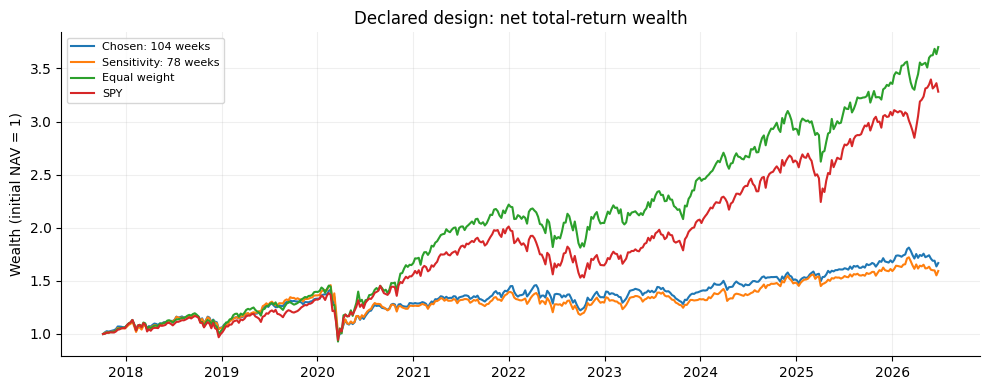

,name,gics_sector_name,Weight
AWK,American Water Works Co Inc,Utilities,8.49%
CME,CME Group Inc,Financials,7.12%
DUK,Duke Energy Corp,Utilities,5.81%
ED,Consolidated Edison Inc,Utilities,5.75%
INTU,Intuit Inc,Information Technology,4.83%
JKHY,Jack Henry & Associates Inc,Financials,4.05%
CHD,Church & Dwight Co Inc,Consumer Staples,3.78%
MSFT,Microsoft Corp,Information Technology,3.41%
SO,Southern Co/The,Utilities,3.20%
KO,Coca-Cola Co/The,Consumer Staples,3.10%


,Chosen: 104 weeks,Sensitivity: 78 weeks,Equal weight
gics_sector_name,,,
Communication Services,9.84%,8.52%,3.94%
Consumer Discretionary,5.06%,5.87%,9.63%
Consumer Staples,27.22%,25.08%,7.00%
Energy,3.69%,3.69%,4.38%
Financials,13.40%,13.12%,15.75%
Health Care,12.57%,13.11%,12.25%
Industrials,4.74%,4.85%,15.32%
Information Technology,7.09%,7.62%,14.22%
Materials,2.51%,2.38%,4.81%


In [19]:
# Change only the allocation window; keep universe, constraints, dates, and costs fixed.
COST_BPS, SHORT_WINDOW = 10.0, 78
short_weights, short_predictions = [], []
for date in rebalance_dates:
    x, f = window_at(date, SHORT_WINDOW)
    model, _ = fit_factor(x, f)
    cov = factor_covariance(model)
    w = long_only_gmv(cov)
    short_weights.append(w)
    short_predictions.append(np.sqrt(52*w @ cov @ w))
short_frame = pd.DataFrame(short_weights, index=rebalance_dates, columns=tickers)
short_book = make_book(short_frame, short_predictions)
# Apply the declared target-turnover cost to weekly returns, without changing gross risk forecasts.
final_books = {
    'Chosen: 104 weeks': make_book(books['Long-only factor GMV']['weights'],
                                  books['Long-only factor GMV']['predicted'], cost_bps=COST_BPS),
    'Sensitivity: 78 weeks': make_book(short_frame, short_predictions, cost_bps=COST_BPS),
    'Equal weight': make_book(books['Equal weight']['weights'], books['Equal weight']['predicted'], cost_bps=COST_BPS),
    'SPY': make_book(spy_weights, spy_predictions, spyx.to_frame('SPY'), cost_bps=COST_BPS),
}
display(Markdown('### Evaluate the declared design and change only the window'))
final_metrics = report_books(final_books)
# The daily VaR estimator still uses 252 days: only the portfolio-choice window changed.
short_daily_risk = forecast_daily({'Sensitivity: 78 weeks': short_book})
chosen_daily_risk = daily_risk[daily_risk.Book == 'Long-only factor GMV'].copy()
chosen_daily_risk['Book'] = 'Chosen: 104 weeks'
final_daily_risk = pd.concat([chosen_daily_risk, short_daily_risk,
                             daily_risk[daily_risk.Book == 'Equal weight']], ignore_index=True)
final_hit_summary = summarize_hits(final_daily_risk)
# Score gross risk delivery against the unchanged declaration; do not tune the pass bands afterward.
evaluation_rows = []
for label, book in final_books.items():
    ratio = book['gross_excess'].std(ddof=1)*np.sqrt(52)/book['predicted'].mean()
    subset = final_hit_summary[(final_hit_summary.Book == label) &
                               (final_hit_summary.Regime == 'Full period') &
                               (final_hit_summary.Method == 'Factor normal')]
    hit_rate = subset['Breach rate'].iloc[0] if len(subset) else np.nan
    evaluation_rows.append({'Book': label, 'Gross realized/predicted': ratio,
                            'Factor-normal breach rate': hit_rate,
                            'Annual cost (bp)': book['costs'].mean()*52*10000,
                            'Risk screen': ('Pass' if 0.8 <= ratio <= 1.2 and 0.03 <= hit_rate <= 0.07 else 'Fail')
                                           if len(subset) else 'Not scored (SPY control)'})
evaluation = pd.DataFrame(evaluation_rows).set_index('Book')
show_table(evaluation, {'Gross realized/predicted': '{:.3f}', 'Factor-normal breach rate': '{:.2%}',
                        'Annual cost (bp)': '{:.2f}', 'Risk screen': '{}'},
           'Declared screen; SPY has no stock-panel factor VaR in this exercise')
final_hit_pivot = final_hit_summary.pivot(index=['Regime', 'Book'], columns='Method', values='Breach rate')
show_table(final_hit_pivot, '{:.2%}', 'Daily sensitivity on the same 453 names and realization dates')

fig, ax = plt.subplots(figsize=(10, 4))
for label, book in final_books.items():
    wealth = (1 + book['excess'] + rf.reindex(oos_dates)).cumprod()
    wealth = pd.concat([pd.Series([1.0], index=[rebalance_dates[0]]), wealth])
    ax.plot(wealth.index, wealth, label=label)
ax.set(title='Declared design: net total-return wealth', ylabel='Wealth (initial NAV = 1)')
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

# Disclose concentration and sector tilts instead of equating long-only with diversification.
last_weights = final_books['Chosen: 104 weeks']['weights'].iloc[-1]
top_holdings = names.loc[last_weights.nlargest(10).index, ['name', 'gics_sector_name']].copy()
top_holdings['Weight'] = last_weights.reindex(top_holdings.index)
show_table(top_holdings, {'name': '{}', 'gics_sector_name': '{}', 'Weight': '{:.2%}'},
           f'Top ten chosen-book holdings at {rebalance_dates[-1].date()}')
sector_exposure = pd.DataFrame({label: book['weights'].T.groupby(sector_labels).sum().mean(axis=1)
                               for label, book in final_books.items() if label != 'SPY'})
show_table(sector_exposure, '{:.2%}', 'Average net sector weights: long-only need not mean sector-neutral')


In [20]:
# Report failure as well as performance: the test is an evaluation, not a search for passing thresholds.
primary = final_metrics.loc['Chosen: 104 weeks']
alternative = final_metrics.loc['Sensitivity: 78 weeks']
display(Markdown(
    f'**Declared result: {evaluation.loc["Chosen: 104 weeks", "Risk screen"]}.** '
    f'The chosen book has a gross realized/predicted volatility ratio of '
    f'**{evaluation.loc["Chosen: 104 weeks", "Gross realized/predicted"]:.3f}** and a factor-normal '
    f'breach rate of **{evaluation.loc["Chosen: 104 weeks", "Factor-normal breach rate"]:.2%}**. '
    f'Its net annualized mean is {primary["Mean"]:.2%}, volatility {primary["Realized vol"]:.2%}, '
    f'Sharpe {primary["Sharpe"]:.2f}, and maximum total-return drawdown {primary["Max drawdown"]:.2%}.\n\n'
    '**Changing only 104 to 78 weeks:** '
    f'net volatility changes by {(alternative["Realized vol"]-primary["Realized vol"])*100:+.2f} percentage points, '
    f'Sharpe by {alternative["Sharpe"]-primary["Sharpe"]:+.2f}, and annual one-way turnover by '
    f'{alternative["Annual one-way turnover"]-primary["Annual one-way turnover"]:+.2f} NAV. '
    f'The shorter-window risk screen is **{evaluation.loc["Sensitivity: 78 weeks", "Risk screen"]}**. '
    'A shorter window trades faster adaptation for fewer observations; this one comparison is a sensitivity check, '
    'not evidence of an optimal window.'))


**Declared result: Fail.** The chosen book has a gross realized/predicted volatility ratio of **1.706** and a factor-normal breach rate of **7.46%**. Its net annualized mean is 4.31%, volatility 14.53%, Sharpe 0.30, and maximum total-return drawdown -31.12%.

**Changing only 104 to 78 weeks:** net volatility changes by +0.20 percentage points, Sharpe by -0.04, and annual one-way turnover by +0.51 NAV. The shorter-window risk screen is **Fail**. A shorter window trades faster adaptation for fewer observations; this one comparison is a sensitivity check, not evidence of an optimal window.

## 7.3

For each choice in 7.1, name the alternative you rejected and the evidence from Sections 2 to 6 that decided it. Close with what your evidence supports and what this sample cannot establish.


### Rejected alternatives and the evidence that matters

| Chosen element | Alternative rejected | Evidence / trade-off |
|---|---|---|
| Static 457-name universe | Dynamic 503-name membership or a selected subset | Common histories keep Sections 1–4 comparisons matched. Section 3 shows that this sacrifices historical investability; dynamic entry dates do not repair an index file containing only later survivors. |
| Sector factors, diagonal residuals | Sample pseudo-inverse; full or sector-block residuals; pure diagonal assets | Section 2 separates fixed-book forecasting from optimized-book errors. Full residuals restore singularity; block residuals add poorly measured hedge directions; pure diagonal assets discard common sector risk. Section 3 supplies shrinkage as a competing stabilization rather than proof that factors are uniquely best. |
| No mean input | Sample, grand-mean-shrunk, or CAPM-implied tangency | Section 4 quantifies noisy means and large exposures. CAPM is the strongest stabilized-mean candidate, and Section 6 does not reject sector CAPM pricing; we reject a return-seeking mandate here, not that evidence. A pure variance mandate needs no mean forecast. |
| Long-only, unit budget, gross 1 | Unconstrained long-short or leveraged 10%-target portfolios | Section 3 measures the cost of ruling out hedges and the change in out-of-sample risk delivery. Section 4's equal forecast volatility does not imply equal realized risk or implementation burden. |
| No extra position cap or sector neutrality | A 2% cap or equal-sector constraints | The Section 3 active set and HHI warn that NNLS can concentrate. Extra constraints would address that concern, but are additional untested designs; this book accepts the disclosed defensive sector tilts rather than claiming that long-only removes them. |
| Minimum variance | Equal weights, mean–variance, or CVaR optimization | Equal weight is the stronger calibration control, but has higher realized volatility. The candidate prioritizes lower absolute volatility, not return maximization. Sections 4–5 show why estimating individual means or optimizing a small tail sample adds fragile inputs. |
| 104 weeks, four-week updates | Shorter windows or more frequent trading | Retains matched Sections 2–5 evidence and limits target turnover. The single 78-week sensitivity checks adaptation versus estimation noise without searching for a winner. |
| 10 bp one-way cost | Frictionless returns or a liquidity-specific cost model | Section 3 turnover shows why zero cost is optimistic for active books. No spreads, volume history, borrow costs, or impact estimates ship; 10 bp is an explicit scenario, not a calibrated execution estimate. |
| Volatility ratio and VaR screen | Choosing the highest in-sample-era Sharpe | Section 2 identifies optimizer-selected risk error; Section 5 tests frequency and severity of tail misses. Return metrics are contextual, not the sole design criterion. |

**Benchmark trade-off.** The chosen book's net volatility is 14.53%, below equal weight's 19.33% and SPY's 18.03%; its drawdown is 31.12%, versus 36.20% and 31.83%. But its 4.31% net excess mean and 0.30 Sharpe trail both controls, and equal weight passes the calibration screen while the candidate fails. Lower realized volatility alone is therefore not evidence of a better all-purpose portfolio. The chosen book is a constrained research candidate for a low-variance mandate, not an approved implementation.

**Conclusion.** The evidence identifies how optimization magnifies risk-estimation error and where constraints reduce implementation fragility. It cannot establish a tradeable historical alpha, a universally best covariance, normal tails, or performance on an untouched sample. The static survivor panel, end-of-sample cap information, overlapping tests, imperfect factor/residual assumptions, and simplified costs limit extrapolation. Failure of the declared risk screen warrants withholding a deployment claim—not relabeling the threshold. Subsequent validation should freeze the design and use genuinely new data, point-in-time membership, and realistic execution costs.

## AI usage and verification

An AI assistant using Copilot SDK in VS Code helped organize the notebook, implement numerical routines, draft explanations, and translate the temporary overviews. It was most useful for rolling-date alignment, covariance/NNLS identities, and consistent portfolio/risk metrics. Verification used clean-kernel execution and separate checks of covariance reconstruction, optimization conditions, forecast timing, volatility scaling, costs, and VaR aggregation; diagnostic logs are not included here. The 20 question cells were checked verbatim against the supplied Brief. The local DFA notebook supplies the joint-alpha convention; the instructor's linked 49-industry page and its charts were inspected directly for Section 6.2. The comparison describes the published pattern without inventing unreported coefficients.